From Models built on bronze, we will bring up to the silver layer the best models: 

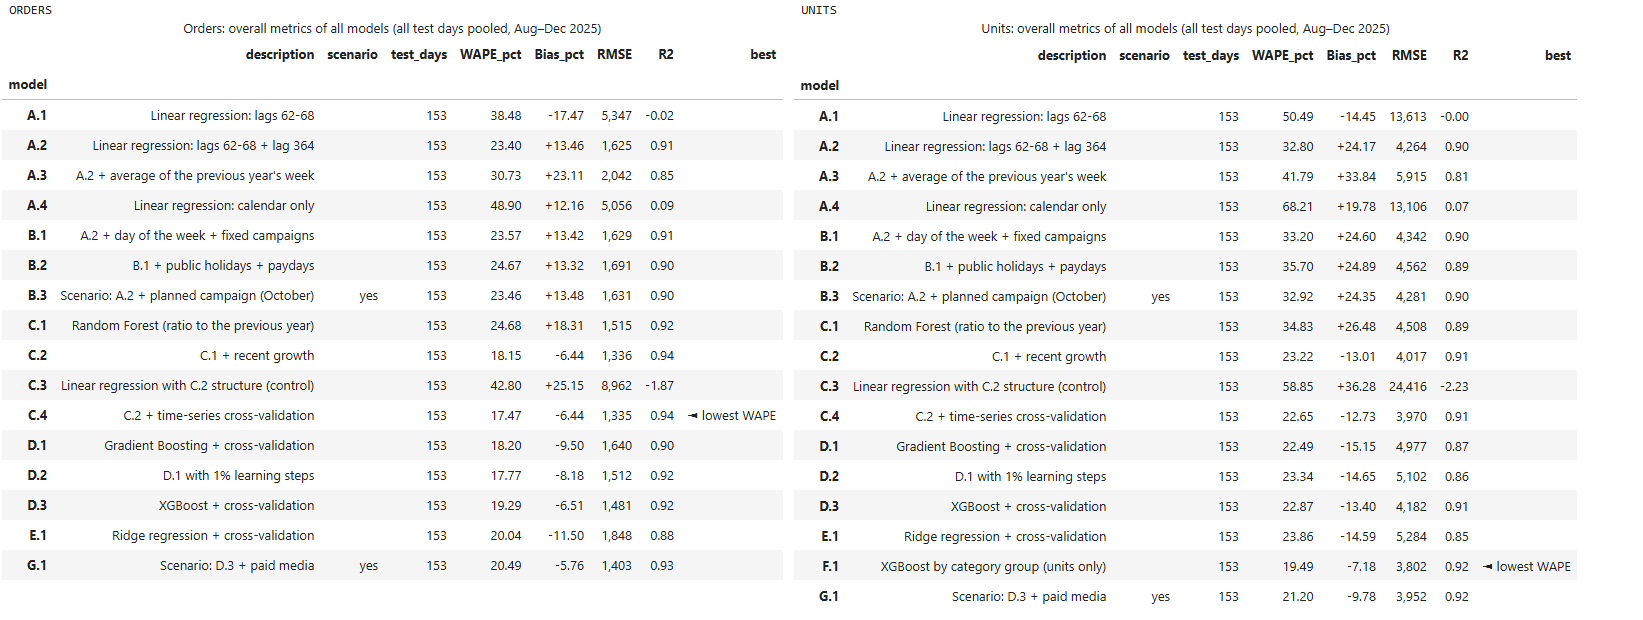

In [1]:
from IPython.display import Image, display

display(Image(filename="ML_on_bronze.png", width=1500))

### Summary of the main models

All models below share the same inputs: the yearly lag (364 days), the most recent known week (lags 62 to 68) and the fixed campaigns (Black Friday, Christmas, Mothers Day, Reyes, Valentines, and Easter and Holy Week). 

They also share the same target: the deviation from the previous year adjusted for recent growth, which is converted back to orders and units after forecasting.

- **C.4: C.2 + time-series cross-validation.** The same Random Forest, but its settings (such as tree depth and the minimum number of days per leaf) are chosen for each test month by time-series cross-validation, using only the training data. It is the best model overall for orders and the most balanced across both targets.

- **D.1: Gradient Boosting + cross-validation.** It replaces the Random Forest with Gradient Boosting, which builds trees one after another, each one correcting the errors of the previous ones. Settings are chosen by time-series cross-validation. It reaches a WAPE close to C.4 for units, but with larger errors on high-volume days (higher RMSE) and a stronger underestimation.

- **D.2: D.1 with 1% learning steps.** The same Gradient Boosting, with a learning rate of 0.01: each new tree corrects only 1% of the remaining error, so the model learns more slowly and more cautiously. It improves orders compared with D.1, but not units.

This were the top5 order models, by WAPE. 

In this notebook, the models are trained and evaluated on data from the **silver layer**, which has already been cleaned and standardised by the dbt pipeline. Each model run is logged to **MLflow**, including its parameters, error metrics, forecast plots and the trained model, so that all experiments are tracked, reproducible and comparable across the baseline, machine learning and deep learning approaches.

## 1. First - built the base table on silver

In [2]:
import pandas as pd
from lakehouse import LakeConfig, connect

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

lake = LakeConfig.from_env()
if "con_b" not in globals():   # reuse the open connection, so the bronze views are kept
    con_b = connect()

# ---------- Configuration ----------
BEGINING_DATE = "2024-01-01"          # None to disable the date filter
COL_EV_MARKET = "Mark_cod"           # None = detect automatically; or write "MARK_COD"
PRODUCT_KEY = "PROD_SPK"          # Product ID in product table
ORDER_DET_KEY = "PROD_SFK"        # matching key in order_det
WO_CAT = "WO_CAT"     # label for products without a category
MARKETS = ["online pt", "online es"]     # markets to keep (case-insensitive)
# ----------------------------------

# Silver tables used by base_ml_silver (file name in the silver bucket, without .parquet)
SILVER_TABLES = {
    "order_cab": "slv_order_cab",
    "order_det": "slv_order_det",
    "events":    "slv_events",
    "product":   "slv_product",
}

def source(table):
    p = lake.uri("silver", f"{SILVER_TABLES[table]}.parquet")
    return f"read_parquet('{p}', union_by_name=true)"

def get_columns(src):
    return con_b.sql(f"DESCRIBE SELECT * FROM {src}").df()["column_name"].tolist()

def find_column(cols, name):
    for c in cols:
        if c.lower() == name.lower():
            return c
    raise ValueError(f"Column '{name}' not found. Available columns: {cols}")

hdr_src, det_src, ev_src, prod_src = source("order_cab"), source("order_det"), source("events"), source("product")

# 0. Required columns
cols_prod = get_columns(prod_src)
COL_PROD_KEY = find_column(cols_prod, PRODUCT_KEY)
COL_CAT = find_column(cols_prod, "CAT_DES_EN")
COL_DET_KEY = find_column(get_columns(det_src), ORDER_DET_KEY)
print(f"product.{COL_PROD_KEY} links to order_det.{COL_DET_KEY}; category = product.{COL_CAT}")

cols_ev = get_columns(ev_src)
if COL_EV_MARKET is None:
    cand = [c for c in cols_ev if "mark" in c.lower()]
    if len(cand) != 1:
        raise ValueError(f"Could not choose the market column in events. Candidates: {cand}.")
    COL_EV_MARKET = cand[0]
print("events: market column =", COL_EV_MARKET)

# 1. order_det lines with product key and category (helper view, in memory)
con_b.sql(f"""
    CREATE OR REPLACE TEMP VIEW det_cat_silver_v AS
    WITH prod_t AS (
        SELECT CAST("{COL_PROD_KEY}" AS VARCHAR) AS prod_key,
               MIN(CAST("{COL_CAT}" AS VARCHAR)) AS prod_cat
        FROM {prod_src}
        GROUP BY 1
    )
    SELECT CAST(d.ORDER_ID AS VARCHAR) AS order_id_str,
           d.ORDER_ID AS order_id_raw,
           d."{COL_DET_KEY}" AS prod_id,
           d."TYPE" AS line_type,
           COALESCE(p.prod_cat, '{WO_CAT}') AS category,
           TRY_CAST(d.PROD_QTY AS DOUBLE) AS qty,
           TRY_CAST(d.AMOUNT_FIXED_RATE_W_DISC_WO_VAT AS DOUBLE) AS amt_w_disc,
           TRY_CAST(d.AMOUNT_FIXED_RATE_WO_DISC_WO_VAT AS DOUBLE) AS amt_wo_disc
    FROM {det_src} d
    LEFT JOIN prod_t p ON p.prod_key = CAST(d."{COL_DET_KEY}" AS VARCHAR)
""")

# 2. Grouped events: one row per campaign family, market and continuous period (helper view, in memory)
#     - event names are cleaned and mapped to families with the same rules used in the baseline notebook
#     - overlapping or consecutive records of the same family in the same market are merged
#       (e.g. "Last Days" + "Last Hours" Valentines -> one Valentines period)
con_b.sql(f"""
    CREATE OR REPLACE TEMP VIEW events_grouped_silver_v AS
    WITH ev_raw AS (
        SELECT UPPER(TRIM(CAST("{COL_EV_MARKET}" AS VARCHAR))) AS market,
               REGEXP_REPLACE(TRIM(CAST(Event AS VARCHAR)), '\\s+', ' ', 'g') AS clean_name,
               TRY_CAST(Start_date AS DATE) AS s,
               TRY_CAST(End_date AS DATE) AS e
        FROM {ev_src}
    ),
    ev_named AS (
        SELECT market, s, e,
               CASE
                   WHEN clean_name ILIKE 'Black Friday%'            THEN 'Black Friday'
                   WHEN clean_name ILIKE 'Clearance%'               THEN 'Clearance'
                   WHEN clean_name ILIKE 'Special Prices%'          THEN 'Special prices'
                   WHEN clean_name ILIKE 'Free Shipping%'           THEN 'Free shipping'
                   WHEN clean_name ILIKE '%Valentines%'             THEN 'Valentines'
                   WHEN clean_name ILIKE '%Mothers Day%'            THEN 'Mothers Day'
                   WHEN clean_name ILIKE '%Christmas%'              THEN 'Christmas'
                   WHEN clean_name ILIKE '%Reyes%'                  THEN 'Reyes'
                   WHEN clean_name IN ('Easter Weeks', 'Holy Week') THEN 'Easter and Holy Week'
                   WHEN clean_name = 'Get your basket ready'        THEN 'Get your basket ready'
                   WHEN clean_name = 'Stock 1'                      THEN 'Stock 1'
                   WHEN clean_name ILIKE 'Apag%'                    THEN 'Iberian blackout'
                   ELSE 'Other'
               END AS campaign
        FROM ev_raw
        WHERE s IS NOT NULL AND e IS NOT NULL AND e >= s          -- valid periods only
    ),
    ordered AS (
        SELECT *,
               MAX(e) OVER (PARTITION BY market, campaign ORDER BY s, e
                            ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING) AS prev_max_end
        FROM ev_named
    ),
    islands AS (
        SELECT *,
               SUM(CASE WHEN prev_max_end IS NULL OR s > prev_max_end + 1 THEN 1 ELSE 0 END)
                   OVER (PARTITION BY market, campaign ORDER BY s, e ROWS UNBOUNDED PRECEDING) AS period_id
        FROM ordered
    )
    SELECT market, campaign,
           MIN(s) AS start_date,
           MAX(e) AS end_date,
           COUNT(*) AS n_source_records
    FROM islands
    GROUP BY market, campaign, period_id
""")

# 3. Base table: one row per order, product and TYPE
markets_sql = ", ".join("'" + m.lower() + "'" for m in MARKETS)
conditions = [f"LOWER(TRIM(CAST(hdr.o_market AS VARCHAR))) IN ({markets_sql})"]
if BEGINING_DATE:
    conditions.append(f"hdr.o_date >= TIMESTAMP '{BEGINING_DATE}'")
where_clause = "WHERE " + " AND ".join(conditions)

con_b.sql(f"""
    CREATE OR REPLACE TEMP VIEW base_ml_silver AS
    WITH hdr AS (
        -- one row per order (order_cab repeats the header for each line)
        SELECT CAST(ORDER_ID AS VARCHAR) AS order_id_str,
               MIN(TRY_CAST(ORDER_DATE AS TIMESTAMP)) AS o_date,
               MIN(ORDER_ORIGIN) AS o_origin,
               MIN(ORDER_CHANEL_TYPE) AS o_channel,
               MIN(CAST(CUSTOMER_ID_FK AS VARCHAR)) AS o_customer,
               MIN(MARK_COD) AS o_market
        FROM {hdr_src}
        GROUP BY 1
    ),
    det_g AS (
        -- sum quantities and amounts per order, product and TYPE
        SELECT order_id_str, MIN(order_id_raw) AS order_g, prod_id, category,
               line_type AS type_g,
               SUM(qty) AS qty_sum, SUM(amt_w_disc) AS amt_w_disc_sum, SUM(amt_wo_disc) AS amt_wo_disc_sum
        FROM det_cat_silver_v
        GROUP BY order_id_str, prod_id, category, line_type
    ),
    ev_t AS (
        SELECT UPPER(TRIM(CAST("{COL_EV_MARKET}" AS VARCHAR))) AS ev_market,
               CAST(Event AS VARCHAR) AS ev_name,
               TRY_CAST(Start_date AS DATE) AS ev_start,
               TRY_CAST(End_date AS DATE) AS ev_end
        FROM {ev_src}
    ),
    pairs AS (
        -- distinct (order day, market) pairs
        SELECT DISTINCT CAST(o_date AS DATE) AS order_day,
               UPPER(TRIM(CAST(o_market AS VARCHAR))) AS market_norm
        FROM hdr
    ),
    ev_pairs AS (
        -- events of the same market whose period contains the order day
        SELECT p.order_day, p.market_norm,
               COUNT(e.ev_market) AS n_events,
               STRING_AGG(DISTINCT e.ev_name, '; ') AS events_list
        FROM pairs p
        LEFT JOIN ev_t e
               ON e.ev_market = p.market_norm AND p.order_day BETWEEN e.ev_start AND e.ev_end
        GROUP BY p.order_day, p.market_norm
    )
    SELECT dg.type_g AS "TYPE",
           dg.order_g AS ORDER_ID,
           dg.prod_id AS PROD_SFK,
           dg.category AS CAT_DES_EN,
           dg.qty_sum AS PROD_QTY,
           dg.amt_w_disc_sum AS AMOUNT_FIXED_RATE_W_DISC_WO_VAT,
           dg.amt_wo_disc_sum AS AMOUNT_FIXED_RATE_WO_DISC_WO_VAT,
           hdr.o_date AS ORDER_DATE,
           hdr.o_origin AS ORDER_ORIGIN,
           hdr.o_channel AS ORDER_CHANEL_TYPE,
           hdr.o_customer AS CUSTOMER_ID_FK,
           hdr.o_market AS MARK_COD,
           COALESCE(evp.n_events, 0) AS n_events,
           evp.events_list AS events_list
    FROM det_g dg
    JOIN hdr ON hdr.order_id_str = dg.order_id_str
    LEFT JOIN ev_pairs evp
           ON evp.order_day = CAST(hdr.o_date AS DATE)
          AND evp.market_norm = UPPER(TRIM(CAST(hdr.o_market AS VARCHAR)))
    {where_clause}
""")

# 4. Validation checks (scope: markets in MARKETS, orders since BEGINING_DATE)
date_cond = f"AND o_date >= TIMESTAMP '{BEGINING_DATE}'" if BEGINING_DATE else ""
con_b.sql(f"""
    CREATE OR REPLACE TEMP VIEW scope_orders_silver_v AS
    SELECT order_id_str
    FROM (
        SELECT CAST(ORDER_ID AS VARCHAR) AS order_id_str,
               MIN(TRY_CAST(ORDER_DATE AS TIMESTAMP)) AS o_date,
               MIN(MARK_COD) AS o_market
        FROM {hdr_src}
        GROUP BY 1
    )
    WHERE LOWER(TRIM(CAST(o_market AS VARCHAR))) IN ({markets_sql})
    {date_cond}
""")
in_scope = "order_id_str IN (SELECT order_id_str FROM scope_orders_silver_v)"

print("1. Products in base_ml_silver with more than one category in product:")
display(con_b.sql(f"""
    WITH prod_cats AS (
        SELECT CAST("{COL_PROD_KEY}" AS VARCHAR) AS k, COUNT(DISTINCT "{COL_CAT}") AS n_cat
        FROM {prod_src} GROUP BY 1
    ),
    used AS (SELECT DISTINCT CAST(PROD_SFK AS VARCHAR) AS k FROM base_ml_silver)
    SELECT COUNT(*) AS products_in_base_ml_silver,
           COUNT(*) FILTER (WHERE pc.n_cat > 1) AS with_several_categories
    FROM used u LEFT JOIN prod_cats pc USING (k)
""").df())

print("2. order_det lines in scope without a category:")
display(con_b.sql(f"""
    SELECT COUNT(*) AS lines_in_scope,
           COUNT(*) FILTER (WHERE category = '{WO_CAT}') AS lines_without_category,
           COALESCE(SUM(qty) FILTER (WHERE category = '{WO_CAT}'), 0) AS qty_without_category
    FROM det_cat_silver_v WHERE {in_scope}
""").df())

print("3. Values lost in numeric conversion (non-null in source, NULL after TRY_CAST), in scope:")
display(con_b.sql(f"""
    SELECT
      COUNT(*) FILTER (WHERE PROD_QTY IS NOT NULL
                         AND TRY_CAST(PROD_QTY AS DOUBLE) IS NULL) AS qty_not_numeric,
      COUNT(*) FILTER (WHERE AMOUNT_FIXED_RATE_W_DISC_WO_VAT IS NOT NULL
                         AND TRY_CAST(AMOUNT_FIXED_RATE_W_DISC_WO_VAT AS DOUBLE) IS NULL) AS amt_w_disc_not_numeric,
      COUNT(*) FILTER (WHERE AMOUNT_FIXED_RATE_WO_DISC_WO_VAT IS NOT NULL
                         AND TRY_CAST(AMOUNT_FIXED_RATE_WO_DISC_WO_VAT AS DOUBLE) IS NULL) AS amt_wo_disc_not_numeric
    FROM {det_src}
    WHERE CAST(ORDER_ID AS VARCHAR) IN (SELECT order_id_str FROM scope_orders_silver_v)
""").df())

print("4. Reconciliation: order_det in scope vs base_ml_silver (difference must be 0):")
recon = con_b.sql(f"""
    SELECT 'order_det (in scope)' AS source,
           COUNT(DISTINCT order_id_str) AS n_orders,
           SUM(qty) AS sum_prod_qty,
           SUM(amt_w_disc) AS sum_amt_w_disc,
           SUM(amt_wo_disc) AS sum_amt_wo_disc
    FROM det_cat_silver_v WHERE {in_scope}
    UNION ALL
    SELECT 'base_ml_silver',
           COUNT(DISTINCT CAST(ORDER_ID AS VARCHAR)),
           SUM(PROD_QTY),
           SUM(AMOUNT_FIXED_RATE_W_DISC_WO_VAT),
           SUM(AMOUNT_FIXED_RATE_WO_DISC_WO_VAT)
    FROM base_ml_silver
""").df().set_index("source")
recon.loc["difference"] = recon.iloc[0] - recon.iloc[1]
display(recon)
display(con_b.sql("""
    SELECT COUNT(*) AS n_rows, MIN(ORDER_DATE) AS first_date, MAX(ORDER_DATE) AS last_date
    FROM base_ml_silver
""").df())

print("5. order_det lines without a header in order_cab (all markets - no market without a header):")
display(con_b.sql(f"""
    SELECT COUNT(*) AS orphan_lines, COALESCE(SUM(qty), 0) AS orphan_qty
    FROM det_cat_silver_v d
    WHERE d.order_id_str NOT IN (SELECT DISTINCT CAST(ORDER_ID AS VARCHAR) FROM {hdr_src})
""").df())

print("6. By TYPE:")
display(con_b.sql("""
    SELECT "TYPE", COUNT(*) AS n_rows, SUM(PROD_QTY) AS sum_prod_qty,
           SUM(AMOUNT_FIXED_RATE_WO_DISC_WO_VAT) AS sum_amount_wo_disc
    FROM base_ml_silver GROUP BY 1 ORDER BY 2 DESC
""").df())

print("7. Distribution of n_events:")
display(con_b.sql("""
    SELECT n_events, COUNT(*) AS n_rows, COUNT(DISTINCT ORDER_ID) AS n_orders
    FROM base_ml_silver GROUP BY n_events ORDER BY n_events
""").df())

print("8. Event data quality (markets in scope):")
display(con_b.sql(f"""
    WITH ev AS (
        SELECT CAST(Event AS VARCHAR) AS name,
               UPPER(TRIM(CAST("{COL_EV_MARKET}" AS VARCHAR))) AS market,
               Start_date, End_date,
               TRY_CAST(Start_date AS DATE) AS s, TRY_CAST(End_date AS DATE) AS e
        FROM {ev_src}
        WHERE LOWER(TRIM(CAST("{COL_EV_MARKET}" AS VARCHAR))) IN ({markets_sql})
    )
    SELECT COUNT(*) AS event_records,
           COUNT(*) FILTER (WHERE s IS NULL OR e IS NULL) AS missing_or_invalid_dates,
           COUNT(*) FILTER (WHERE e < s) AS end_before_start,
           COUNT(*) - (SELECT COUNT(*) FROM (SELECT DISTINCT name, market, s, e FROM ev)) AS duplicated_records
    FROM ev
""").df())

print("9. Key (ORDER_ID, PROD_SFK, TYPE): rows vs distinct keys (must be equal):")
display(con_b.sql("""
    SELECT COUNT(*) AS n_rows,
           COUNT(DISTINCT (ORDER_ID, PROD_SFK, "TYPE")) AS distinct_keys
    FROM base_ml_silver
""").df())

product.prod_spk links to order_det.prod_sfk; category = product.cat_des_en
events: market column = Mark_cod
1. Products in base_ml_silver with more than one category in product:


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,products_in_base_ml_silver,with_several_categories
0,63141,0


2. order_det lines in scope without a category:


,lines_in_scope,lines_without_category,qty_without_category
0,6438815,0,0.00


3. Values lost in numeric conversion (non-null in source, NULL after TRY_CAST), in scope:


... (15 outputs left out)

,event_records,missing_or_invalid_dates,end_before_start,duplicated_records
0,106,0,0,0


9. Key (ORDER_ID, PROD_SFK, TYPE): rows vs distinct keys (must be equal):


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,n_rows,distinct_keys
0,6438239,6438239


In [3]:
display(con_b.sql("""
    SELECT * FROM base_ml_silver
    ORDER BY ORDER_DATE, ORDER_ID, PROD_SFK, "TYPE"
    LIMIT 10
""").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,TYPE,ORDER_ID,PROD_SFK,CAT_DES_EN,PROD_QTY,AMOUNT_FIXED_RATE_W_DISC_WO_VAT,AMOUNT_FIXED_RATE_WO_DISC_WO_VAT,ORDER_DATE,ORDER_ORIGIN,ORDER_CHANEL_TYPE,CUSTOMER_ID_FK,MARK_COD,n_events,events_list
0,SALE,900004330601,5790008,Hand Bag,1.00,11.60,12.89,2024-01-01,PARFOIS,DESKTOP,159540580,Online ES,0,NaN
1,SALE,900004330601,5791397,Hand Bag,1.00,11.60,12.89,2024-01-01,PARFOIS,DESKTOP,159540580,Online ES,0,NaN
2,SALE,900004330601,5812342,Hand Bag,1.00,11.60,12.89,2024-01-01,PARFOIS,DESKTOP,159540580,Online ES,0,NaN
3,RETURN,900004330602,5779173,Sunglasses,-1.00,-9.91,-9.91,2024-01-01,PARFOIS,DESKTOP,159540434,Online ES,0,NaN
4,SALE,900004330602,5779173,Sunglasses,1.00,9.91,9.91,2024-01-01,PARFOIS,DESKTOP,159540434,Online ES,0,NaN
5,SALE,900004330602,5853219,Jewellery,1.00,2.47,2.47,2024-01-01,PARFOIS,DESKTOP,159540434,Online ES,0,NaN
6,SALE,900004330605,5803352,Hand Bag,1.00,13.88,13.88,2024-01-01,PARFOIS,DESKTOP,1710092,Online ES,0,NaN
7,SALE,900004330607,5811101,Silver,1.00,19.50,19.50,2024-01-01,PARFOIS,DESKTOP,159541331,Online PT,1,Clearance
8,RETURN,900004330614,5809430,Footwear,-1.00,-22.80,-22.80,2024-01-01,PARFOIS,DESKTOP,862049,Online ES,0,NaN
9,SALE,900004330614,5809430,Footwear,1.00,22.80,22.80,2024-01-01,PARFOIS,DESKTOP,862049,Online ES,0,NaN


### C.4: Random Forest +  Cross Validation

In [4]:
# ============================================================
# C.4 - Random Forest with time-series cross-validation to choose the settings
# Inputs: yearly lag, recent lags and fixed campaigns; target: deviation from the previous year
# adjusted for recent growth. For each test month, the settings of the forest
# (tree depth, minimum days per leaf) are chosen by mini-tests inside the training data only:
# train on the past, leave a one-month gap, validate on the next 4 weeks.
# The final model is then trained on all training days and forecasts the test month.
# Forecasting rule: each month is forecast with data up to the last day
# of the month two months before (e.g. September 2025 -> data up to 31 July 2025)
# Extra target: daily sales value (revenue, with discounts, without VAT). It is forecast with the
# same design, but it is complementary only: the model choice is based on orders and units.
# ============================================================
import numpy as np
from sklearn.ensemble import RandomForestRegressor

# ---------- Configuration ----------
C4_ID = "C.4"                                                       # short name used in the result tables
C4_NAME = "C.4 Random Forest (time-series cross-validation)"   # full name used in charts
C4_RECENT_LAGS = list(range(62, 69))      # one full week, always known at the time of the forecast
C4_YEARLY_LAG = 364                       # 52 weeks: same weekday of the previous year
C4_GROWTH_WINDOW = 28                     # recent growth measured over 4 full weeks...
C4_GROWTH_END_LAG = 62                    # ...ending 62 days before the day (always known at the time of the forecast)
C4_CAMPAIGNS = {                          # campaign family (as in events_grouped_v) -> feature name
    "Black Friday": "camp_black_friday",
    "Christmas": "camp_christmas",
    "Mothers Day": "camp_mothers_day",
    "Reyes": "camp_reyes",
    "Valentines": "camp_valentines",
    "Easter and Holy Week": "camp_easter_holy_week",
}
C4_RF_FIXED = dict(max_features=0.5, random_state=42, n_jobs=-1)   # settings not tuned
C4_PARAM_GRID = [                                                    # settings compared by cross-validation
    {"max_depth": d, "min_samples_leaf": l} for d in (4, 6, 8) for l in (7, 14)
]
C4_DEFAULT = {"max_depth": 6, "min_samples_leaf": 7}  # default settings, used if the training period is too short for a fold
C4_TREES_CV, C4_TREES_FINAL = 200, 500   # fewer trees in the mini-tests (faster), 500 in the final model
C4_CV_FOLDS = 3          # up to 3 mini-tests per test month
C4_CV_VALID_DAYS = 28    # each mini-test covers 4 weeks...
C4_CV_GAP_DAYS = 30      # ...starting one month after the end of its training data, as in the forecasting rule
C4_CV_MIN_TRAIN = 28     # minimum training days in a mini-test
TARGETS = ["orders", "units"]                 # main targets (used for the model choice and in the comparison cells)
C4_TARGETS = TARGETS + ["sales"]              # targets forecast in this cell: main targets + sales value (extra)
TEST_MONTHS = ["2025-08", "2025-09", "2025-10", "2025-11", "2025-12"]
# ----------------------------------

# 0. Check that base_ml and events_grouped_v exist (temporary views, lost when the kernel restarts)
for view in ["base_ml_silver", "events_grouped_silver_v"]:
    try:
        con_b.sql(f"SELECT 1 FROM {view} LIMIT 1")
    except Exception:
        raise RuntimeError(f"{view} not found: run the cell that creates base_ml_silver (including step 1b) first.")

# 1. Daily series of the targets (SALE lines only)
c4_daily = con_b.sql("""
    SELECT CAST(ORDER_DATE AS DATE) AS day,
           COUNT(DISTINCT ORDER_ID) AS orders,
           SUM(PROD_QTY) AS units,
           SUM(AMOUNT_FIXED_RATE_W_DISC_WO_VAT) AS sales     -- sales value: with discounts, without VAT
    FROM base_ml_silver
    WHERE "TYPE" = 'SALE'
    GROUP BY 1
    ORDER BY 1
""").df()
c4_daily["day"] = pd.to_datetime(c4_daily["day"])
c4_daily = c4_daily.set_index("day").asfreq("D", fill_value=0)   # every day present, missing days = 0
print(f"Daily series: {len(c4_daily)} days, from {c4_daily.index.min().date()} to {c4_daily.index.max().date()}")

# 2. Lag features, recent growth and target
#    ratio         = value of the day / value of the same weekday of the previous year
#    recent growth = sum of the 28 days ending 62 days before the day / same 28 days of the previous year
#    deviation     = ratio / recent growth (the target of the trees)
for t in C4_TARGETS:
    for lag in C4_RECENT_LAGS + [C4_YEARLY_LAG]:
        c4_daily[f"{t}_lag_{lag}"] = c4_daily[t].shift(lag)
    recent = c4_daily[t].rolling(C4_GROWTH_WINDOW).sum().shift(C4_GROWTH_END_LAG)
    recent_last_year = recent.shift(C4_YEARLY_LAG)
    c4_daily[f"{t}_recent_growth"] = recent / recent_last_year.replace(0, np.nan)
    c4_daily[f"{t}_ratio"] = c4_daily[t] / c4_daily[f"{t}_lag_{C4_YEARLY_LAG}"].replace(0, np.nan)
    c4_daily[f"{t}_deviation"] = c4_daily[f"{t}_ratio"] / c4_daily[f"{t}_recent_growth"]

# 3. Fixed campaigns relative to the previous year
#    +1 = campaign on the day but not on the equivalent day last year; -1 = the opposite; 0 = same situation
camp = con_b.sql(f"""
    SELECT campaign, start_date, end_date
    FROM events_grouped_silver_v
    WHERE LOWER(market) IN ({markets_sql})
""").df()
camp_active = pd.DataFrame(0, index=c4_daily.index, columns=list(C4_CAMPAIGNS.values()))
for family, col in C4_CAMPAIGNS.items():
    for _, row in camp[camp["campaign"] == family].iterrows():
        camp_active.loc[pd.Timestamp(row["start_date"]):pd.Timestamp(row["end_date"]), col] = 1
camp_diff = (camp_active - camp_active.shift(C4_YEARLY_LAG).fillna(0).astype(int)).add_suffix("_vs_ly")
c4_daily = c4_daily.join(camp_diff)
C4_CAMP = list(camp_diff.columns)

print("\nCampaign days in 2025 that differ from the previous year:")
diff_2025 = camp_diff[camp_diff.index.year == 2025]
display(pd.DataFrame({"days_+1": (diff_2025 == 1).sum(), "days_-1": (diff_2025 == -1).sum()}).rename_axis("feature"))

def c4_features(t):
    return [f"{t}_lag_{lag}" for lag in C4_RECENT_LAGS + [C4_YEARLY_LAG]] + C4_CAMP

# 4. Error metrics (as defined in the "Error metrics" section)
def error_metrics(actual, forecast):
    actual, forecast = np.asarray(actual, dtype=float), np.asarray(forecast, dtype=float)
    err = forecast - actual
    return {
        "WAPE_pct": 100 * np.abs(err).sum() / actual.sum(),
        "Bias_pct": 100 * err.sum() / actual.sum(),          # > 0 overestimates, < 0 underestimates
        "RMSE": np.sqrt(np.mean(err ** 2)),
        "R2": 1 - np.sum(err ** 2) / np.sum((actual - actual.mean()) ** 2),
    }

# 5. Time-series cross-validation inside the training data
#    The training days are split into successive mini-tests: train on the past, leave a one-month gap,
#    validate on the next 4 weeks. The test months are never used to choose the settings.
def cv_folds(n_days):
    """Positions (train, validation) of up to C4_CV_FOLDS mini-tests, the last one ending at the cutoff."""
    folds = []
    for k in range(C4_CV_FOLDS):
        valid_end = n_days - k * C4_CV_VALID_DAYS
        valid_start = valid_end - C4_CV_VALID_DAYS
        train_end = valid_start - C4_CV_GAP_DAYS
        if train_end < C4_CV_MIN_TRAIN:
            break
        folds.append((np.arange(0, train_end), np.arange(valid_start, valid_end)))
    return folds[::-1]

def fit_forecast(train_part, apply_part, t, params, n_trees):
    """Train on train_part and return the forecast in orders/units for apply_part."""
    features = c4_features(t)
    model = RandomForestRegressor(n_estimators=n_trees, **params, **C4_RF_FIXED)
    model.fit(train_part[features], train_part[f"{t}_deviation"])
    forecast = (model.predict(apply_part[features])
                * apply_part[f"{t}_recent_growth"].to_numpy()
                * apply_part[f"{t}_lag_{C4_YEARLY_LAG}"].to_numpy())
    return forecast, model

def choose_params(train_t, t):
    """Return the settings with the lowest average WAPE in the mini-tests, and that WAPE."""
    folds = cv_folds(len(train_t))
    if not folds:
        return C4_DEFAULT, np.nan, 0
    scores = []
    for params in C4_PARAM_GRID:
        wapes = []
        for tr, va in folds:
            fc, _ = fit_forecast(train_t.iloc[tr], train_t.iloc[va], t, params, C4_TREES_CV)
            wapes.append(error_metrics(train_t.iloc[va][t], fc)["WAPE_pct"])
        scores.append(np.mean(wapes))
    best = int(np.argmin(scores))
    return C4_PARAM_GRID[best], scores[best], len(folds)

# 6. Evaluation by calendar month (settings chosen by cross-validation, then final model on all training days)
c4_results, c4_predictions, c4_importance, c4_chosen = [], [], {}, []
for month in TEST_MONTHS:
    month_start = pd.Timestamp(f"{month}-01")
    month_end = month_start + pd.offsets.MonthEnd(0)
    cutoff = month_start - pd.DateOffset(months=1) - pd.Timedelta(days=1)   # last day of data available

    train = c4_daily[c4_daily.index <= cutoff]
    test = c4_daily[(c4_daily.index >= month_start) & (c4_daily.index <= month_end)]

    # leakage check: every lag used in the test month refers to a day on or before the cutoff
    assert (test.index - pd.Timedelta(days=min(C4_RECENT_LAGS))).max() <= cutoff

    for t in C4_TARGETS:
        features = c4_features(t)
        train_t = train.dropna(subset=features + [f"{t}_deviation"])   # recent growth exists from late March 2025

        params, cv_wape, n_folds = choose_params(train_t, t)
        forecast, model = fit_forecast(train_t, test, t, params, C4_TREES_FINAL)
        actual = test[t].to_numpy()
        c4_importance[(t, month)] = pd.Series(model.feature_importances_, index=features)
        c4_chosen.append({"target": t, "month": month, "cv_folds": n_folds, **params, "cv_WAPE_pct": cv_wape})

        c4_results.append({
            "model": C4_ID,
            "target": t,
            "month": month,
            "data_up_to": cutoff.date(),
            "train_from": train_t.index.min().date(),
            "train_days": len(train_t),
            "recent_growth": test[f"{t}_recent_growth"].mean(),          # average growth the model starts from
            "actual_growth": test[t].sum() / test[f"{t}_lag_{C4_YEARLY_LAG}"].sum(),   # growth that actually happened
            **error_metrics(actual, forecast),
        })
        c4_predictions.append(pd.DataFrame({
            "model": C4_ID, "day": test.index, "target": t, "month": month,
            "actual": actual, "forecast": forecast,
        }))

c4_results = pd.DataFrame(c4_results)
c4_predictions = pd.concat(c4_predictions, ignore_index=True)
c4_chosen = pd.DataFrame(c4_chosen)

print("\nSettings chosen by cross-validation for each test month (cv_folds = number of mini-tests;")
print("0 = training period too short, default settings used):")
display(c4_chosen)

# 7. Results
print("\nResults by month:")
display(c4_results)

print("Overall results (all test days pooled):")
c4_overall = pd.DataFrame([
    {"model": C4_ID, "target": t, **error_metrics(g["actual"], g["forecast"])}
    for t, g in c4_predictions.groupby("target")
])
display(c4_overall)

print("recent_growth = growth vs the previous year known at the time of the forecast (average over the month);")
print("actual_growth = growth vs the previous year that actually happened in the month.")

# 8. Feature importance (average over the test months): which inputs the trees use most
print("Feature importance (share of the error reduction, average over the test months):")
importance = pd.DataFrame({
    t: pd.concat([s.rename(lambda f: f.replace(f"{t}_", "")) for (tt, _), s in c4_importance.items() if tt == t], axis=1).mean(axis=1)
    for t in C4_TARGETS
}).sort_values(TARGETS[0], ascending=False)
display((100 * importance).round(1))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Daily series: 731 days, from 2024-01-01 to 2025-12-31

Campaign days in 2025 that differ from the previous year:


,days_+1,days_-1
feature,,
camp_black_friday_vs_ly,0,0
camp_christmas_vs_ly,2,2
camp_mothers_day_vs_ly,3,0
camp_reyes_vs_ly,2,1
camp_valentines_vs_ly,3,4
camp_easter_holy_week_vs_ly,17,17



Settings chosen by cross-validation for each test month (cv_folds = number of mini-tests;
0 = training period too short, default settings used):


,target,month,cv_folds,max_depth,min_samples_leaf,cv_WAPE_pct
0,orders,2025-08,1,4,14,28.83
1,units,2025-08,1,4,14,30.38
2,sales,2025-08,1,4,14,28.38
3,orders,2025-09,2,4,14,38.37
4,units,2025-09,2,4,14,43.66
5,sales,2025-09,2,4,14,34.40
6,orders,2025-10,3,4,14,31.38
7,units,2025-10,3,4,14,37.61
8,sales,2025-10,3,6,14,29.24
9,orders,2025-11,3,4,14,24.00



Results by month:


,model,target,month,data_up_to,train_from,train_days,recent_growth,actual_growth,WAPE_pct,Bias_pct,RMSE,R2
0,C.4,orders,2025-08,2025-06-30,2025-03-29,94,1.18,1.15,19.07,-17.22,806.91,-0.59
1,C.4,units,2025-08,2025-06-30,2025-03-29,94,1.22,1.22,30.95,-30.48,"2,447.79",-1.86
2,C.4,sales,2025-08,2025-06-30,2025-03-29,94,1.35,1.19,20.46,-18.22,"15,401.32",-0.79
3,C.4,orders,2025-09,2025-07-31,2025-03-29,125,1.34,1.07,18.87,-17.66,637.63,-2.73
4,C.4,units,2025-09,2025-07-31,2025-03-29,125,1.41,1.10,21.98,-21.98,"1,185.27",-5.06
5,C.4,sales,2025-09,2025-07-31,2025-03-29,125,1.48,1.20,16.67,-12.61,"13,018.07",-2.12
6,C.4,orders,2025-10,2025-08-31,2025-03-29,156,1.26,1.04,13.47,4.66,499.62,-0.95
7,C.4,units,2025-10,2025-08-31,2025-03-29,156,1.37,1.04,12.89,-2.19,810.37,-0.81
8,C.4,sales,2025-10,2025-08-31,2025-03-29,156,1.30,1.10,20.42,10.46,"18,442.96",-2.70
9,C.4,orders,2025-11,2025-09-30,2025-03-29,186,1.12,1.25,13.45,-5.97,"2,199.95",0.96


Overall results (all test days pooled):


,model,target,WAPE_pct,Bias_pct,RMSE,R2
0,C.4,orders,17.47,-6.45,"1,335.43",0.94
1,C.4,sales,20.03,-6.79,"35,048.84",0.92
2,C.4,units,22.64,-12.78,"3,970.75",0.91


recent_growth = growth vs the previous year known at the time of the forecast (average over the month);
actual_growth = growth vs the previous year that actually happened in the month.
Feature importance (share of the error reduction, average over the test months):


,orders,units,sales
lag_364,39.40,50.10,36.80
lag_68,17.00,14.00,14.60
lag_67,14.90,10.80,15.50
lag_66,9.60,6.20,7.30
lag_62,5.80,5.00,8.00
lag_64,4.40,3.60,5.80
lag_65,4.30,4.50,3.30
lag_63,3.90,5.50,3.90
camp_easter_holy_week_vs_ly,0.70,0.40,4.80
camp_black_friday_vs_ly,0.00,0.00,0.00


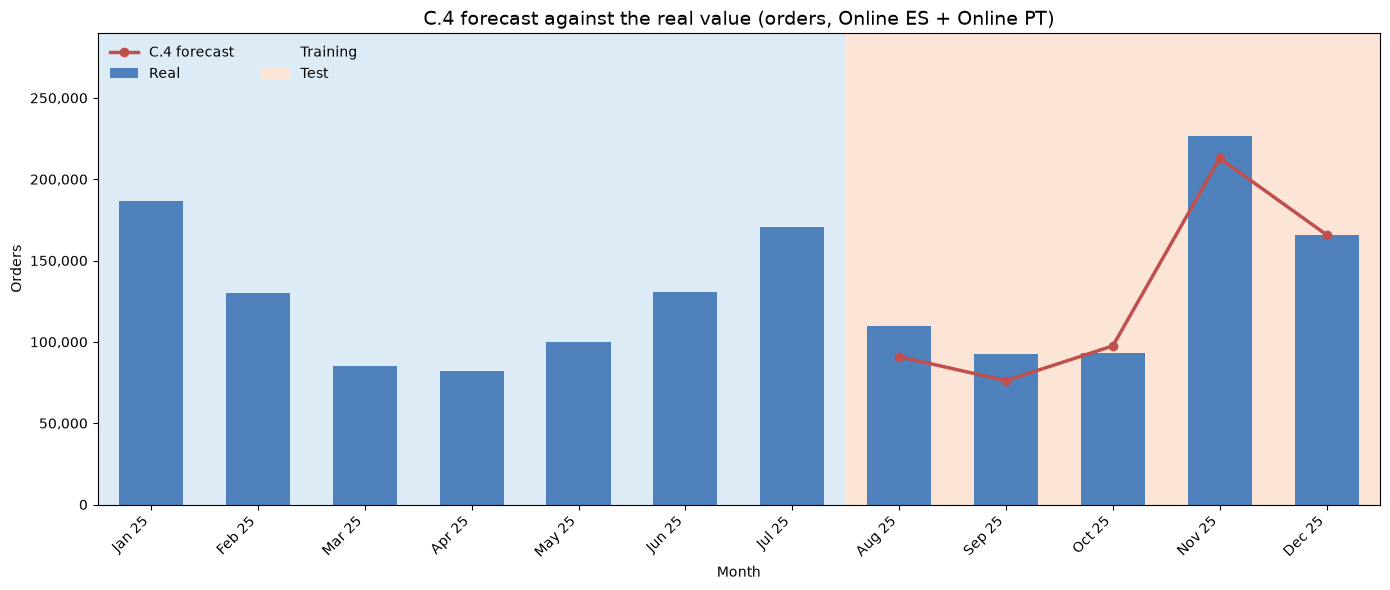

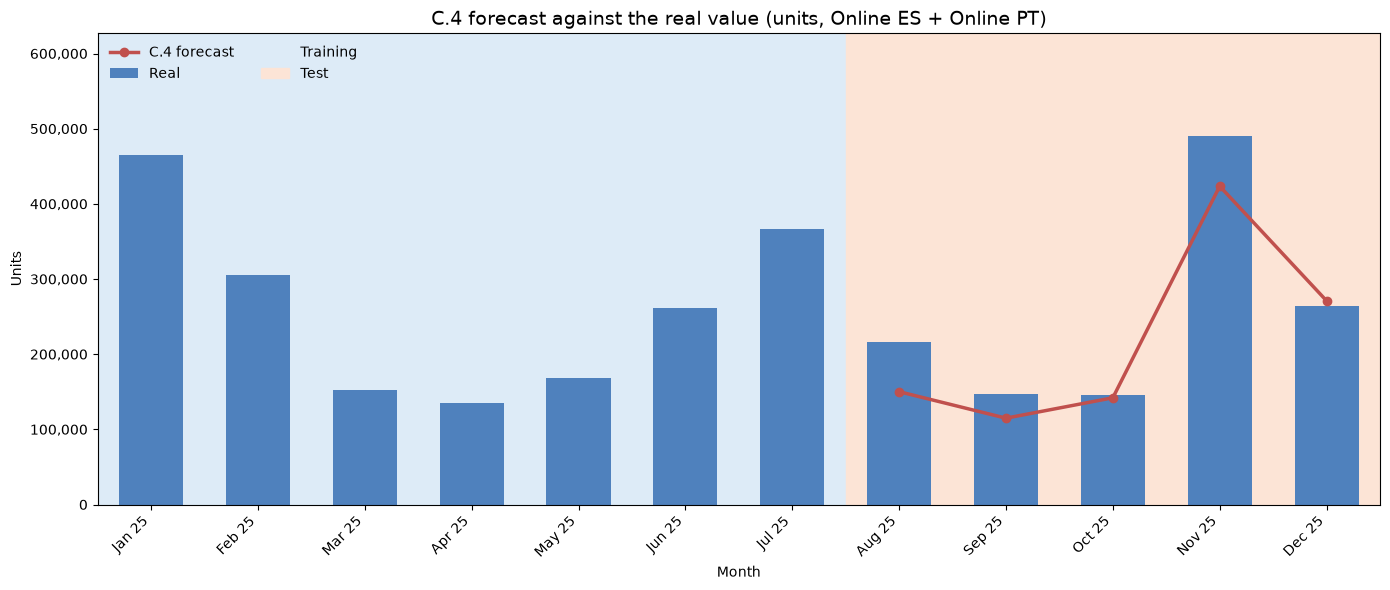

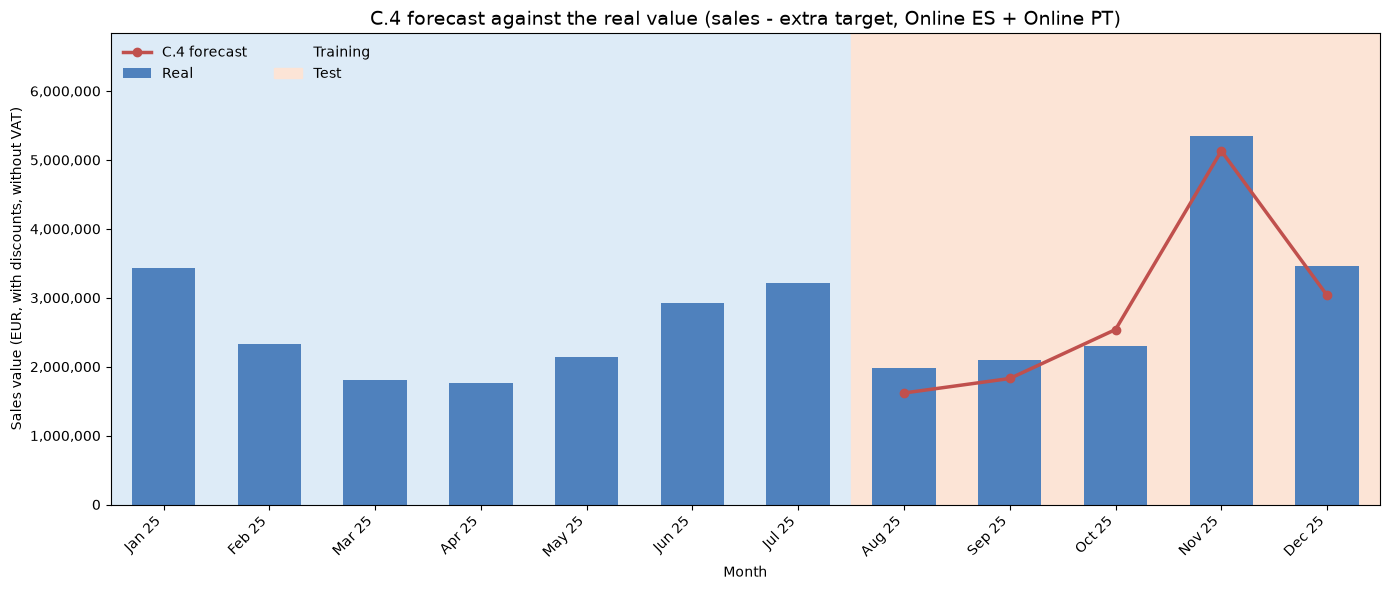

1. Overall metrics (all test days pooled; sales = extra target, not used for the model choice):


,WAPE_pct,Bias_pct,RMSE,R2
target,,,,
orders,17.47,-6.45,"1,335.43",0.94
units,22.64,-12.78,"3,970.75",0.91
sales,20.03,-6.79,"35,048.84",0.92


2. Daily error by month - WAPE (%) and Bias (%) (positive Bias = overestimates, negative = underestimates):


WAPE_pct             Bias_pct              
target    orders units sales   orders  units  sales
month                                              
2025-08    19.07 30.95 20.46   -17.22 -30.48 -18.22
2025-09    18.87 21.98 16.67   -17.66 -21.98 -12.61
2025-10    13.47 12.89 20.42     4.66  -2.19  10.46
2025-11    13.45 19.45 19.72    -5.97 -13.57  -3.99
2025-12    23.35 27.50 22.04     0.06   2.47 -12.49

3. Monthly totals: actual, forecast and error (error = forecast - actual):


actual  forecast   error  error_pct
target month                                        
orders 2025-08   109819     90910  -18909     -17.20
       2025-09    92480     76147  -16333     -17.70
       2025-10    93177     97522    4345       4.70
       2025-11   226443    212916  -13527      -6.00
       2025-12   165749    165851     102       0.10
units  2025-08   215903    150094  -65809     -30.50
       2025-09   147237    114870  -32367     -22.00
       2025-10   145159    141979   -3180      -2.20
       2025-11   489972    423475  -66497     -13.60
       2025-12   264466    271004    6538       2.50
sales  2025-08  1978446   1618071 -360375     -18.20
       2025-09  2092389   1828591 -263798     -12.60
       2025-10  2298605   2538963  240358      10.50
       2025-11  5344322   5130853 -213469      -4.00
       2025-12  3466734   3033722 -433013     -12.50

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

# ---------- Chart settings ----------
PLOT_FROM = "2025-01"        # first month shown (None = full period); the forecasts only exist in the test months
MODEL_NAME = "C.4"
FORECAST_COLOUR = "#C0504D"
Y_LABELS = {"orders": "Orders", "units": "Units", "sales": "Sales value (EUR, with discounts, without VAT)"}
# ------------------------------------

if "c4_predictions" not in globals():
    raise RuntimeError("c4_predictions not found: run the C.4 model cell first.")
preds = c4_predictions.copy()
preds["day"] = pd.to_datetime(preds["day"])
preds["month_start"] = preds["day"].dt.to_period("M").dt.to_timestamp()

# 1. Charts: actual monthly totals (bars) and monthly forecast totals (line), one chart per target
monthly_fc = preds.pivot_table(index="month_start", columns="target", values="forecast", aggfunc="sum")
tab_all = c4_daily[C4_TARGETS].resample("MS").sum()
if PLOT_FROM:
    tab_all = tab_all[tab_all.index >= pd.Timestamp(f"{PLOT_FROM}-01")]
months = tab_all.index
x = list(range(len(months)))
first_test = months.get_loc(pd.Timestamp(f"{TEST_MONTHS[0]}-01"))
last_test = months.get_loc(pd.Timestamp(f"{TEST_MONTHS[-1]}-01"))

for t in C4_TARGETS:
    fig, ax = plt.subplots(figsize=(14, 6))
    ax.axvspan(-0.5, first_test - 0.5, color='#DDEBF7'); ax.axvspan(first_test - 0.5, last_test + 0.5, color='#FCE4D6')   # training and test
    ax.bar(x, tab_all[t], color='#4F81BD', width=0.6, label='Real')
    series = monthly_fc[t].reindex(months)
    ax.plot(x, series, color=FORECAST_COLOUR, linestyle="-", marker="o", linewidth=2.5, label=f"{MODEL_NAME} forecast")
    ax.set_xticks(x); ax.set_xticklabels([m.strftime('%b %y') for m in months], rotation=45, ha='right')
    ax.set_xlim(-0.5, len(months) - 0.5)
    title_extra = " - extra target" if t not in TARGETS else ""
    ax.set_title(f'{MODEL_NAME} forecast against the real value ({t}{title_extra}, Online ES + Online PT)', fontsize=14)
    ax.set_xlabel('Month'); ax.set_ylabel(Y_LABELS.get(t, t.capitalize()))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{int(v):,}'))
    ax.set_ylim(0, np.nanmax(np.concatenate([tab_all[t].to_numpy(dtype=float), series.to_numpy(dtype=float)])) * 1.28)
    handles, labels = ax.get_legend_handles_labels()
    handles += [Patch(color='#DDEBF7', label='Training'), Patch(color='#FCE4D6', label='Test')]
    ax.legend(handles=handles, frameon=False, ncol=2, loc='upper left', fontsize=10)
    fig.tight_layout()
    plt.show()

# 2. Overall metrics (all test days pooled)
overall = pd.DataFrame([
    {"target": t, **error_metrics(g["actual"], g["forecast"])}
    for t, g in preds.groupby("target")
]).set_index("target").reindex(C4_TARGETS)
print("1. Overall metrics (all test days pooled; sales = extra target, not used for the model choice):")
display(overall.round(2))

# 3. Daily error metrics by month: WAPE and Bias side by side
monthly_metrics = pd.DataFrame([
    {"target": t, "month": mo, **error_metrics(g["actual"], g["forecast"])}
    for (t, mo), g in preds.groupby(["target", "month"])
])
print("2. Daily error by month - WAPE (%) and Bias (%) (positive Bias = overestimates, negative = underestimates):")
display(monthly_metrics.pivot_table(index="month", columns="target", values=["WAPE_pct", "Bias_pct"])
        .reindex(columns=C4_TARGETS, level=1)[["WAPE_pct", "Bias_pct"]].round(2))

# 4. Error in the monthly total: actual vs forecast total for the month and the difference
totals = preds.groupby(["target", "month"]).agg(actual=("actual", "sum"), forecast=("forecast", "sum")).reset_index()
totals["error"] = totals["forecast"] - totals["actual"]
totals["error_pct"] = (100 * totals["error"] / totals["actual"]).round(1)
for col in ["actual", "forecast", "error"]:
    totals[col] = totals[col].round(0).astype(int)
totals["target"] = pd.Categorical(totals["target"], categories=C4_TARGETS, ordered=True)
print("3. Monthly totals: actual, forecast and error (error = forecast - actual):")
display(totals.sort_values(["target", "month"]).set_index(["target", "month"]))

### D.1: Gradient Boosting with time-series cross-validation

In [6]:
# ============================================================
# D.1 - Gradient Boosting with time-series cross-validation to choose the settings
# Inputs: yearly lag, recent lags and fixed campaigns; target = deviation
# from the previous year adjusted for recent growth.
# Trees are trained one after another, each correcting 5% of the remaining error.
# For each test month, the tree depth and the number of trees are chosen by mini-tests inside
# the training data only: train on the past, leave a one-month gap, validate on the next 4 weeks.
# The final model is then trained on all training days and forecasts the test month.
# Forecasting rule: each month is forecast with data up to the last day
# of the month two months before (e.g. September 2025 -> data up to 31 July 2025)
# Extra target: daily sales value (revenue, with discounts, without VAT). It is forecast with the
# same design, but it is complementary only: the model choice is based on orders and units.
# ============================================================
import numpy as np
from sklearn.ensemble import GradientBoostingRegressor

# ---------- Configuration ----------
D1_ID = "D.1"                                                       # short name used in the result tables
D1_NAME = "D.1 Gradient Boosting (time-series cross-validation)"   # full name used in charts
D1_RECENT_LAGS = list(range(62, 69))      # one full week, always known at the time of the forecast
D1_YEARLY_LAG = 364                       # 52 weeks: same weekday of the previous year
D1_GROWTH_WINDOW = 28                     # recent growth measured over 4 full weeks...
D1_GROWTH_END_LAG = 62                    # ...ending 62 days before the day (always known at the time of the forecast)
D1_CAMPAIGNS = {                          # campaign family (as in events_grouped_v) -> feature name
    "Black Friday": "camp_black_friday",
    "Christmas": "camp_christmas",
    "Mothers Day": "camp_mothers_day",
    "Reyes": "camp_reyes",
    "Valentines": "camp_valentines",
    "Easter and Holy Week": "camp_easter_holy_week",
}
D1_GB_FIXED = dict(
    learning_rate=0.05,      # small steps: each tree corrects only 5% of the remaining error
    subsample=0.8,           # each tree sees a random 80% of the training days (more robust)
    min_samples_leaf=7,      # each final answer is based on at least one week of days
    random_state=42,         # reproducible results
)
D1_DEPTHS = (2, 3)           # simple trees: 2 or 3 questions each (chosen by cross-validation)
D1_MAX_TREES = 600           # longest queue of trees tested; the best length is chosen by cross-validation
D1_DEFAULT = {"max_depth": 3, "n_estimators": 300}   # used if the training period is too short for a mini-test
D1_CV_FOLDS = 3          # up to 3 mini-tests per test month
D1_CV_VALID_DAYS = 28    # each mini-test covers 4 weeks...
D1_CV_GAP_DAYS = 30      # ...starting one month after the end of its training data, as in the forecasting rule
D1_CV_MIN_TRAIN = 28     # minimum training days in a mini-test
TARGETS = ["orders", "units"]                 # main targets (used for the model choice and in the comparison cells)
D1_TARGETS = TARGETS + ["sales"]              # targets forecast in this cell: main targets + sales value (extra)
TEST_MONTHS = ["2025-08", "2025-09", "2025-10", "2025-11", "2025-12"]
# ----------------------------------

# 0. Check that base_ml and events_grouped_v exist (temporary views, lost when the kernel restarts)
for view in ["base_ml_silver", "events_grouped_silver_v"]:
    try:
        con_b.sql(f"SELECT 1 FROM {view} LIMIT 1")
    except Exception:
        raise RuntimeError(f"{view} not found: run the cell that creates base_ml_silver (including step 1b) first.")

# 1. Daily series of the targets (SALE lines only)
d1_daily = con_b.sql("""
    SELECT CAST(ORDER_DATE AS DATE) AS day,
           COUNT(DISTINCT ORDER_ID) AS orders,
           SUM(PROD_QTY) AS units,
           SUM(AMOUNT_FIXED_RATE_W_DISC_WO_VAT) AS sales     -- sales value: with discounts, without VAT
    FROM base_ml_silver
    WHERE "TYPE" = 'SALE'
    GROUP BY 1
    ORDER BY 1
""").df()
d1_daily["day"] = pd.to_datetime(d1_daily["day"])
d1_daily = d1_daily.set_index("day").asfreq("D", fill_value=0)   # every day present, missing days = 0
print(f"Daily series: {len(d1_daily)} days, from {d1_daily.index.min().date()} to {d1_daily.index.max().date()}")

# 2. Lag features, recent growth and target
#    ratio         = value of the day / value of the same weekday of the previous year
#    recent growth = sum of the 28 days ending 62 days before the day / same 28 days of the previous year
#    deviation     = ratio / recent growth (the target of the trees)
for t in D1_TARGETS:
    for lag in D1_RECENT_LAGS + [D1_YEARLY_LAG]:
        d1_daily[f"{t}_lag_{lag}"] = d1_daily[t].shift(lag)
    recent = d1_daily[t].rolling(D1_GROWTH_WINDOW).sum().shift(D1_GROWTH_END_LAG)
    recent_last_year = recent.shift(D1_YEARLY_LAG)
    d1_daily[f"{t}_recent_growth"] = recent / recent_last_year.replace(0, np.nan)
    d1_daily[f"{t}_ratio"] = d1_daily[t] / d1_daily[f"{t}_lag_{D1_YEARLY_LAG}"].replace(0, np.nan)
    d1_daily[f"{t}_deviation"] = d1_daily[f"{t}_ratio"] / d1_daily[f"{t}_recent_growth"]

# 3. Fixed campaigns relative to the previous year
#    +1 = campaign on the day but not on the equivalent day last year; -1 = the opposite; 0 = same situation
camp = con_b.sql(f"""
    SELECT campaign, start_date, end_date
    FROM events_grouped_silver_v
    WHERE LOWER(market) IN ({markets_sql})
""").df()
camp_active = pd.DataFrame(0, index=d1_daily.index, columns=list(D1_CAMPAIGNS.values()))
for family, col in D1_CAMPAIGNS.items():
    for _, row in camp[camp["campaign"] == family].iterrows():
        camp_active.loc[pd.Timestamp(row["start_date"]):pd.Timestamp(row["end_date"]), col] = 1
camp_diff = (camp_active - camp_active.shift(D1_YEARLY_LAG).fillna(0).astype(int)).add_suffix("_vs_ly")
d1_daily = d1_daily.join(camp_diff)
D1_CAMP = list(camp_diff.columns)

print("\nCampaign days in 2025 that differ from the previous year:")
diff_2025 = camp_diff[camp_diff.index.year == 2025]
display(pd.DataFrame({"days_+1": (diff_2025 == 1).sum(), "days_-1": (diff_2025 == -1).sum()}).rename_axis("feature"))

def d1_features(t):
    return [f"{t}_lag_{lag}" for lag in D1_RECENT_LAGS + [D1_YEARLY_LAG]] + D1_CAMP

# 4. Error metrics (as defined in the "Error metrics" section)
def error_metrics(actual, forecast):
    actual, forecast = np.asarray(actual, dtype=float), np.asarray(forecast, dtype=float)
    err = forecast - actual
    return {
        "WAPE_pct": 100 * np.abs(err).sum() / actual.sum(),
        "Bias_pct": 100 * err.sum() / actual.sum(),          # > 0 overestimates, < 0 underestimates
        "RMSE": np.sqrt(np.mean(err ** 2)),
        "R2": 1 - np.sum(err ** 2) / np.sum((actual - actual.mean()) ** 2),
    }

# 5. Time-series cross-validation inside the training data
#    The training days are split into successive mini-tests: train on the past, leave a one-month gap,
#    validate on the next 4 weeks. The test months are never used to choose the settings.
def cv_folds(n_days):
    """Positions (train, validation) of up to D1_CV_FOLDS mini-tests, the last one ending at the cutoff."""
    folds = []
    for k in range(D1_CV_FOLDS):
        valid_end = n_days - k * D1_CV_VALID_DAYS
        valid_start = valid_end - D1_CV_VALID_DAYS
        train_end = valid_start - D1_CV_GAP_DAYS
        if train_end < D1_CV_MIN_TRAIN:
            break
        folds.append((np.arange(0, train_end), np.arange(valid_start, valid_end)))
    return folds[::-1]

def to_volume(deviation, part, t):
    """Convert a forecast deviation into orders/units/sales: deviation x recent growth x previous year."""
    return (deviation * part[f"{t}_recent_growth"].to_numpy()
            * part[f"{t}_lag_{D1_YEARLY_LAG}"].to_numpy())

def fit_forecast(train_part, apply_part, t, params):
    """Train on train_part and return the forecast in orders/units/sales for apply_part."""
    features = d1_features(t)
    model = GradientBoostingRegressor(**params, **D1_GB_FIXED)
    model.fit(train_part[features], train_part[f"{t}_deviation"])
    return to_volume(model.predict(apply_part[features]), apply_part, t), model

def choose_params(train_t, t):
    """Choose the tree depth and the number of trees with the lowest average WAPE in the mini-tests.
    For each depth, one model with D1_MAX_TREES trees is trained per mini-test, and its forecast is
    read after every tree (staged_predict), so all queue lengths are compared at once."""
    folds = cv_folds(len(train_t))
    if not folds:
        return D1_DEFAULT, np.nan, 0
    features = d1_features(t)
    best = (None, np.inf)
    for depth in D1_DEPTHS:
        wape_by_trees = []
        for tr, va in folds:
            part_tr, part_va = train_t.iloc[tr], train_t.iloc[va]
            model = GradientBoostingRegressor(n_estimators=D1_MAX_TREES, max_depth=depth, **D1_GB_FIXED)
            model.fit(part_tr[features], part_tr[f"{t}_deviation"])
            actual = part_va[t].to_numpy()
            wape_by_trees.append([
                100 * np.abs(to_volume(dev, part_va, t) - actual).sum() / actual.sum()
                for dev in model.staged_predict(part_va[features])
            ])
        mean_wape = np.mean(wape_by_trees, axis=0)          # average over the mini-tests, for each queue length
        n_trees = int(np.argmin(mean_wape)) + 1
        if mean_wape[n_trees - 1] < best[1]:
            best = ({"max_depth": depth, "n_estimators": n_trees}, mean_wape[n_trees - 1])
    return best[0], best[1], len(folds)

# 6. Evaluation by calendar month (settings chosen by cross-validation, then final model on all training days)
d1_results, d1_predictions, d1_importance, d1_chosen = [], [], {}, []
for month in TEST_MONTHS:
    month_start = pd.Timestamp(f"{month}-01")
    month_end = month_start + pd.offsets.MonthEnd(0)
    cutoff = month_start - pd.DateOffset(months=1) - pd.Timedelta(days=1)   # last day of data available

    train = d1_daily[d1_daily.index <= cutoff]
    test = d1_daily[(d1_daily.index >= month_start) & (d1_daily.index <= month_end)]

    # leakage check: every lag used in the test month refers to a day on or before the cutoff
    assert (test.index - pd.Timedelta(days=min(D1_RECENT_LAGS))).max() <= cutoff

    for t in D1_TARGETS:
        features = d1_features(t)
        train_t = train.dropna(subset=features + [f"{t}_deviation"])   # recent growth exists from late March 2025

        params, cv_wape, n_folds = choose_params(train_t, t)
        forecast, model = fit_forecast(train_t, test, t, params)
        actual = test[t].to_numpy()
        d1_importance[(t, month)] = pd.Series(model.feature_importances_, index=features)
        d1_chosen.append({"target": t, "month": month, "cv_folds": n_folds, **params, "cv_WAPE_pct": cv_wape})

        d1_results.append({
            "model": D1_ID,
            "target": t,
            "month": month,
            "data_up_to": cutoff.date(),
            "train_from": train_t.index.min().date(),
            "train_days": len(train_t),
            "recent_growth": test[f"{t}_recent_growth"].mean(),          # average growth the model starts from
            "actual_growth": test[t].sum() / test[f"{t}_lag_{D1_YEARLY_LAG}"].sum(),   # growth that actually happened
            **error_metrics(actual, forecast),
        })
        d1_predictions.append(pd.DataFrame({
            "model": D1_ID, "day": test.index, "target": t, "month": month,
            "actual": actual, "forecast": forecast,
        }))

d1_results = pd.DataFrame(d1_results)
d1_predictions = pd.concat(d1_predictions, ignore_index=True)
d1_chosen = pd.DataFrame(d1_chosen)

print("\nSettings chosen by cross-validation for each test month (cv_folds = number of mini-tests;")
print("0 = training period too short, default settings used):")
display(d1_chosen)

# 7. Results
print("\nResults by month:")
display(d1_results)

print("Overall results (all test days pooled):")
d1_overall = pd.DataFrame([
    {"model": D1_ID, "target": t, **error_metrics(g["actual"], g["forecast"])}
    for t, g in d1_predictions.groupby("target")
])
display(d1_overall)

print("recent_growth = growth vs the previous year known at the time of the forecast (average over the month);")
print("actual_growth = growth vs the previous year that actually happened in the month.")

# 8. Feature importance (average over the test months): which inputs the trees use most
print("Feature importance (share of the error reduction, average over the test months):")
importance = pd.DataFrame({
    t: pd.concat([s.rename(lambda f: f.replace(f"{t}_", "")) for (tt, _), s in d1_importance.items() if tt == t], axis=1).mean(axis=1)
    for t in D1_TARGETS
}).sort_values(TARGETS[0], ascending=False)
display((100 * importance).round(1))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Daily series: 731 days, from 2024-01-01 to 2025-12-31

Campaign days in 2025 that differ from the previous year:


,days_+1,days_-1
feature,,
camp_black_friday_vs_ly,0,0
camp_christmas_vs_ly,2,2
camp_mothers_day_vs_ly,3,0
camp_reyes_vs_ly,2,1
camp_valentines_vs_ly,3,4
camp_easter_holy_week_vs_ly,17,17



Settings chosen by cross-validation for each test month (cv_folds = number of mini-tests;
0 = training period too short, default settings used):


,target,month,cv_folds,max_depth,n_estimators,cv_WAPE_pct
0,orders,2025-08,1,2,1,29.67
1,units,2025-08,1,2,1,31.04
2,sales,2025-08,1,2,1,28.45
3,orders,2025-09,2,3,1,39.54
4,units,2025-09,2,3,1,43.12
5,sales,2025-09,2,2,592,31.69
6,orders,2025-10,3,3,4,32.98
7,units,2025-10,3,3,8,38.36
8,sales,2025-10,3,3,499,28.39
9,orders,2025-11,3,3,8,21.67



Results by month:


,model,target,month,data_up_to,train_from,train_days,recent_growth,actual_growth,WAPE_pct,Bias_pct,RMSE,R2
0,D.1,orders,2025-08,2025-06-30,2025-03-29,94,1.18,1.15,22.98,-22.06,925.96,-1.09
1,D.1,units,2025-08,2025-06-30,2025-03-29,94,1.22,1.22,31.52,-31.02,"2,453.43",-1.87
2,D.1,sales,2025-08,2025-06-30,2025-03-29,94,1.35,1.19,17.97,-16.30,"13,858.52",-0.45
3,D.1,orders,2025-09,2025-07-31,2025-03-29,125,1.34,1.07,9.27,8.16,362.56,-0.21
4,D.1,units,2025-09,2025-07-31,2025-03-29,125,1.41,1.10,9.92,4.40,584.20,-0.47
5,D.1,sales,2025-09,2025-07-31,2025-03-29,125,1.48,1.20,17.09,10.97,"17,063.56",-4.36
6,D.1,orders,2025-10,2025-08-31,2025-03-29,156,1.26,1.04,15.14,7.93,538.23,-1.27
7,D.1,units,2025-10,2025-08-31,2025-03-29,156,1.37,1.04,15.33,7.64,930.66,-1.39
8,D.1,sales,2025-10,2025-08-31,2025-03-29,156,1.30,1.10,30.04,18.37,"27,894.21",-7.46
9,D.1,orders,2025-11,2025-09-30,2025-03-29,186,1.12,1.25,19.29,-16.04,"3,149.70",0.92


Overall results (all test days pooled):


,model,target,WAPE_pct,Bias_pct,RMSE,R2
0,D.1,orders,18.20,-9.50,"1,639.51",0.90
1,D.1,sales,22.99,-9.44,"48,318.44",0.85
2,D.1,units,22.51,-15.13,"4,974.45",0.87


recent_growth = growth vs the previous year known at the time of the forecast (average over the month);
actual_growth = growth vs the previous year that actually happened in the month.
Feature importance (share of the error reduction, average over the test months):


,orders,units,sales
lag_364,60.00,74.60,43.90
lag_68,23.80,11.60,17.10
lag_66,4.80,1.80,2.90
camp_easter_holy_week_vs_ly,2.80,1.80,19.10
lag_62,2.40,1.70,3.80
lag_67,2.30,0.70,3.40
lag_63,2.00,2.30,2.30
lag_64,1.60,2.20,3.20
lag_65,0.30,3.20,4.20
camp_black_friday_vs_ly,0.00,0.00,0.00


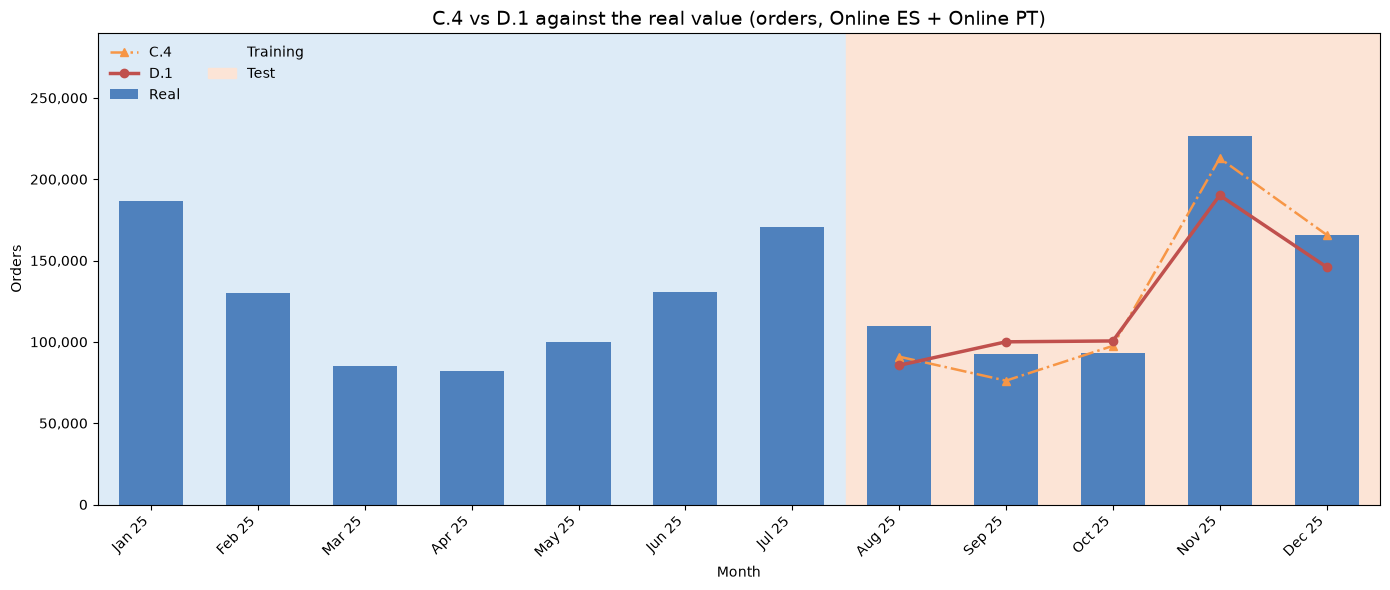

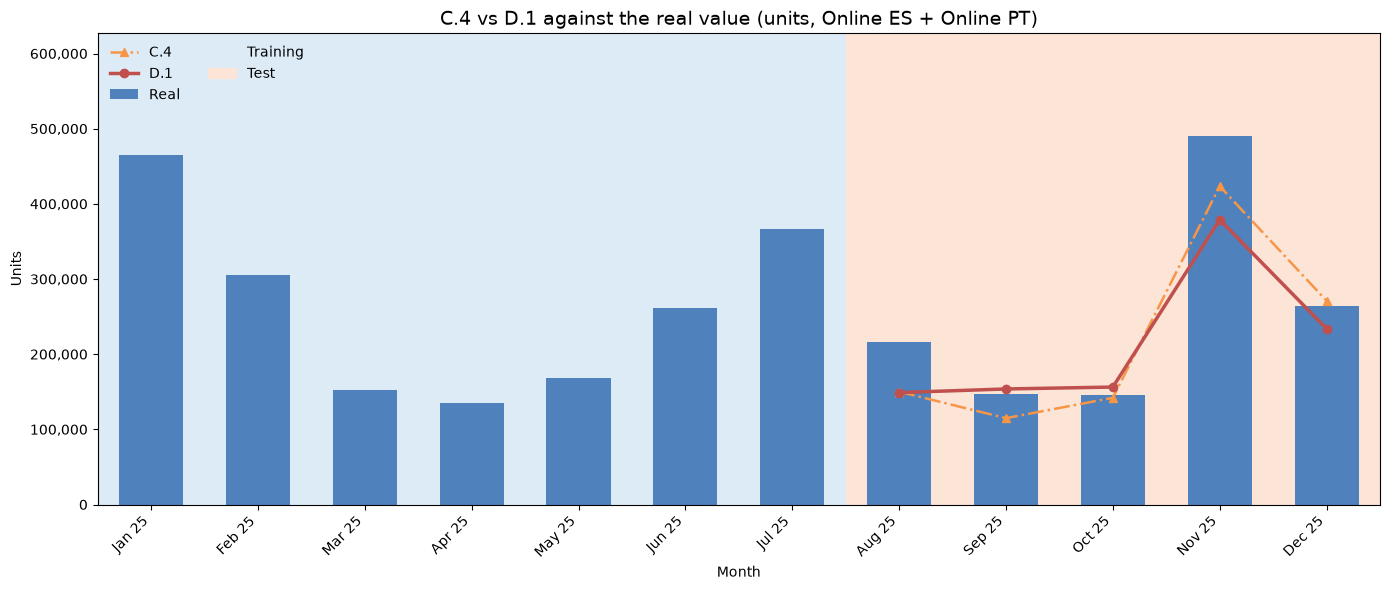

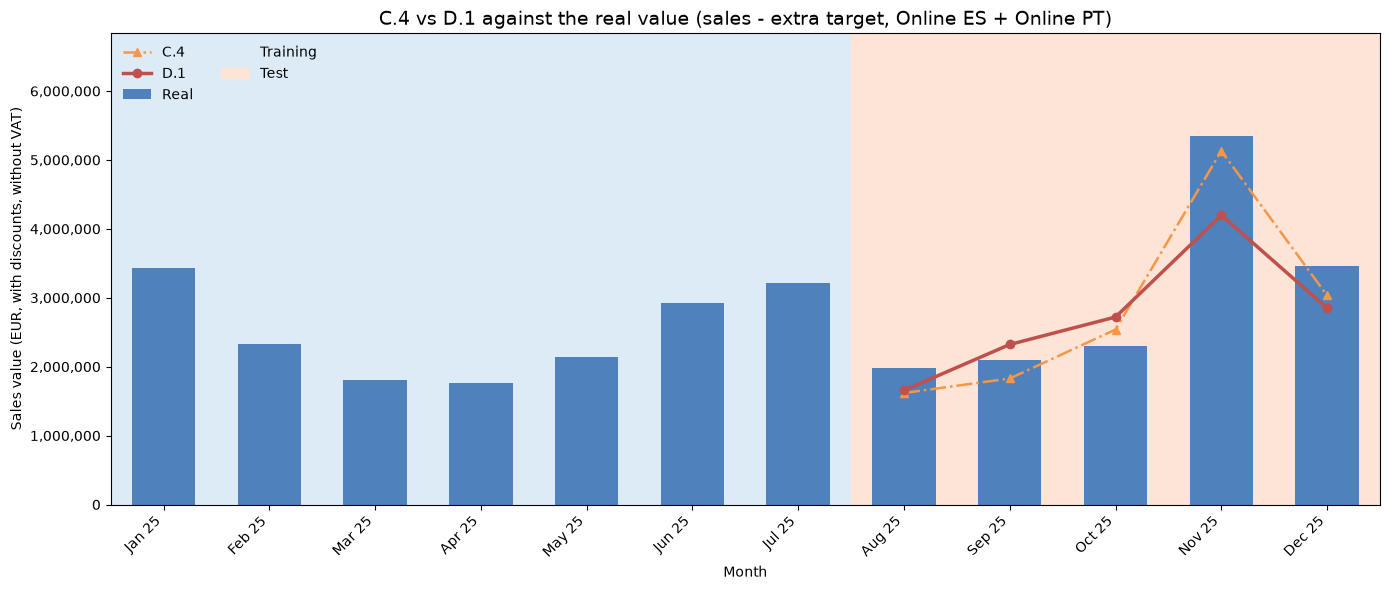

1. Overall metrics (all test days pooled; sales = extra target, not used for the model choice):


WAPE_pct  Bias_pct      RMSE   R2
target model                                   
orders C.4       17.47     -6.45  1,335.43 0.94
       D.1       18.20     -9.50  1,639.51 0.90
units  C.4       22.64    -12.78  3,970.75 0.91
       D.1       22.51    -15.13  4,974.45 0.87
sales  C.4       20.03     -6.79 35,048.84 0.92
       D.1       22.99     -9.44 48,318.44 0.85

2. Change from C.4 to each model (negative WAPE and RMSE changes = better than C.4):


,,WAPE_pct change,Bias_pct change,RMSE change,R2 change
target,model,,,,
orders,D.1,0.73,-3.06,304.08,-0.03
units,D.1,-0.13,-2.36,"1,003.70",-0.05
sales,D.1,2.96,-2.65,"13,269.60",-0.07


3. Daily error by month - WAPE (%):


model            C.4   D.1
target month              
orders 2025-08 19.07 22.98
       2025-09 18.87  9.27
       2025-10 13.47 15.14
       2025-11 13.45 19.29
       2025-12 23.35 20.24
units  2025-08 30.95 31.52
       2025-09 21.98  9.92
       2025-10 12.89 15.33
       2025-11 19.45 24.17
       2025-12 27.50 23.03
sales  2025-08 20.46 17.97
       2025-09 16.67 17.09
       2025-10 20.42 30.04
       2025-11 19.72 23.56
       2025-12 22.04 23.88

4. Daily error by month - Bias (%) (positive = overestimates, negative = underestimates):


model             C.4    D.1
target month                
orders 2025-08 -17.22 -22.06
       2025-09 -17.66   8.16
       2025-10   4.66   7.93
       2025-11  -5.97 -16.04
       2025-12   0.06 -11.91
units  2025-08 -30.48 -31.02
       2025-09 -21.98   4.40
       2025-10  -2.19   7.64
       2025-11 -13.57 -22.67
       2025-12   2.47 -11.57
sales  2025-08 -18.22 -16.30
       2025-09 -12.61  10.97
       2025-10  10.46  18.37
       2025-11  -3.99 -21.43
       2025-12 -12.49 -17.80

5. Monthly totals: actual, forecast and error of each model (error = forecast - actual):


actual forecast            error          error_pct       
model                        C.4      D.1     C.4      D.1       C.4    D.1
target month                                                               
orders 2025-08   109819    90910    85588  -18909   -24231    -17.20 -22.10
       2025-09    92480    76147   100028  -16333     7548    -17.70   8.20
       2025-10    93177    97522   100563    4345     7386      4.70   7.90
       2025-11   226443   212916   190132  -13527   -36311     -6.00 -16.00
       2025-12   165749   165851   146012     102   -19737      0.10 -11.90
units  2025-08   215903   150094   148926  -65809   -66977    -30.50 -31.00
       2025-09   147237   114870   153718  -32367     6481    -22.00   4.40
       2025-10   145159   141979   156250   -3180    11091     -2.20   7.60
       2025-11   489972   423475   378916  -66497  -111056    -13.60 -22.70
       2025-12   264466   271004   233864    6538   -30602      2.50 -11.60
sales  2025-08  1978446  1618071  1655909 -360375  -322536    -18.20 -16.30
       2025-09  2092389  1828591  2321979 -263798   229590    -12.60  11.00
       2025-10  2298605  2538963  2720813  240358   422207     10.50  18.40
       2025-11  5344322  5130853  4199009 -213469 -1145313     -4.00 -21.40
       2025-12  3466734  3033722  2849759 -433013  -616975    -12.50 -17.80

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

# ---------- Chart settings ----------
PLOT_FROM = "2025-01"        # first month shown (None = full period); the forecasts only exist in the test months
# model -> (predictions table, colour, line style, marker); the first model is the reference
COMPARE = {
    "C.4": ("c4_predictions", "#F79646", "-.", "^"),   # reference: random forest
    "D.1": ("d1_predictions", "#C0504D", "-",  "o"),   # gradient boosting
}
HIGHLIGHT = "D.1"            # model drawn with a thicker line
PLOT_TARGETS = D1_TARGETS    # orders, units and sales (extra target)
Y_LABELS = {"orders": "Orders", "units": "Units", "sales": "Sales value (EUR, with discounts, without VAT)"}
# ------------------------------------

for name, (var, *_style) in COMPARE.items():
    if var not in globals():
        raise RuntimeError(f"{var} not found: run the {name} model cell first.")
preds = pd.concat([globals()[var].assign(model=name) for name, (var, *_s) in COMPARE.items()], ignore_index=True)
preds = preds[preds["target"].isin(PLOT_TARGETS)]
preds["day"] = pd.to_datetime(preds["day"])
preds["month_start"] = preds["day"].dt.to_period("M").dt.to_timestamp()
model_names = list(COMPARE)

# 1. Charts: actual monthly totals (bars) and monthly forecast totals of each model (lines)
monthly_fc = preds.pivot_table(index="month_start", columns=["model", "target"], values="forecast", aggfunc="sum")
tab_all = d1_daily[PLOT_TARGETS].resample("MS").sum()
if PLOT_FROM:
    tab_all = tab_all[tab_all.index >= pd.Timestamp(f"{PLOT_FROM}-01")]
months = tab_all.index
x = list(range(len(months)))
first_test = months.get_loc(pd.Timestamp(f"{TEST_MONTHS[0]}-01"))
last_test = months.get_loc(pd.Timestamp(f"{TEST_MONTHS[-1]}-01"))

for t in PLOT_TARGETS:
    fig, ax = plt.subplots(figsize=(14, 6))
    ax.axvspan(-0.5, first_test - 0.5, color='#DDEBF7'); ax.axvspan(first_test - 0.5, last_test + 0.5, color='#FCE4D6')   # training and test
    ax.bar(x, tab_all[t], color='#4F81BD', width=0.6, label='Real')
    values = [tab_all[t].to_numpy(dtype=float)]
    for name in model_names:
        if (name, t) not in monthly_fc.columns:
            continue                                   # a model without this target is skipped
        _, colour, style, marker = COMPARE[name]
        series = monthly_fc[(name, t)].reindex(months)
        values.append(series.to_numpy(dtype=float))
        ax.plot(x, series, color=colour, linestyle=style, marker=marker,
                linewidth=2.5 if name == HIGHLIGHT else 1.8, label=name)
    ax.set_xticks(x); ax.set_xticklabels([m.strftime('%b %y') for m in months], rotation=45, ha='right')
    ax.set_xlim(-0.5, len(months) - 0.5)
    title_extra = " - extra target" if t not in TARGETS else ""
    ax.set_title(f'{" vs ".join(model_names)} against the real value ({t}{title_extra}, Online ES + Online PT)', fontsize=14)
    ax.set_xlabel('Month'); ax.set_ylabel(Y_LABELS.get(t, t.capitalize()))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{int(v):,}'))
    ax.set_ylim(0, np.nanmax(np.concatenate(values)) * 1.28)
    handles, labels = ax.get_legend_handles_labels()
    handles += [Patch(color='#DDEBF7', label='Training'), Patch(color='#FCE4D6', label='Test')]
    ax.legend(handles=handles, frameon=False, ncol=2, loc='upper left', fontsize=10)
    fig.tight_layout()
    plt.show()

# 2. Overall metrics (all test days pooled) and change from the reference model
overall = pd.DataFrame([
    {"target": t, "model": m, **error_metrics(g["actual"], g["forecast"])}
    for (m, t), g in preds.groupby(["model", "target"])
]).set_index(["target", "model"])
overall = overall.reindex(pd.MultiIndex.from_product([PLOT_TARGETS, model_names], names=["target", "model"])).dropna(how="all")
print("1. Overall metrics (all test days pooled; sales = extra target, not used for the model choice):")
display(overall.round(2))

reference = model_names[0]
change = pd.concat({
    m: overall.xs(m, level="model") - overall.xs(reference, level="model") for m in model_names[1:]
}, names=["model"]).swaplevel().reindex(PLOT_TARGETS, level=0)
change.columns = [f"{c} change" for c in change.columns]
print(f"2. Change from {reference} to each model (negative WAPE and RMSE changes = better than {reference}):")
display(change.round(2))

# 3. Daily error metrics by month: WAPE and Bias side by side
monthly_metrics = pd.DataFrame([
    {"target": t, "month": mo, "model": m, **error_metrics(g["actual"], g["forecast"])}
    for (m, t, mo), g in preds.groupby(["model", "target", "month"])
])
monthly_metrics["target"] = pd.Categorical(monthly_metrics["target"], categories=PLOT_TARGETS, ordered=True)
print("3. Daily error by month - WAPE (%):")
display(monthly_metrics.pivot_table(index=["target", "month"], columns="model", values="WAPE_pct", observed=True)[model_names].round(2))
print("4. Daily error by month - Bias (%) (positive = overestimates, negative = underestimates):")
display(monthly_metrics.pivot_table(index=["target", "month"], columns="model", values="Bias_pct", observed=True)[model_names].round(2))

# 4. Error in the monthly total: actual vs forecast total for the month and the difference
totals = preds.groupby(["target", "month", "model"]).agg(actual=("actual", "sum"), forecast=("forecast", "sum")).reset_index()
totals["error"] = totals["forecast"] - totals["actual"]
totals["error_pct"] = 100 * totals["error"] / totals["actual"]
totals["target"] = pd.Categorical(totals["target"], categories=PLOT_TARGETS, ordered=True)
monthly_totals = totals.pivot_table(index=["target", "month"], columns="model", values=["forecast", "error", "error_pct"], observed=True)
monthly_totals = monthly_totals[["forecast", "error", "error_pct"]]
for col in monthly_totals.columns:
    monthly_totals[col] = monthly_totals[col].round(1) if col[0] == "error_pct" else monthly_totals[col].round(0).astype(int)
monthly_totals.insert(0, ("actual", ""), totals.groupby(["target", "month"], observed=True)["actual"].first().round(0).astype(int))
print("5. Monthly totals: actual, forecast and error of each model (error = forecast - actual):")
display(monthly_totals)

### F.1: XGBoost by category group (units only)

In [8]:
%pip install xgboost

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [9]:
# ============================================================
# F.1 - XGBoost by category group: units (and sales value) forecast for each product category group
# One row per day and group, a single model for all groups, the group as an input,
# rows weighted by the size of the group in the previous year.
# Inputs: the group's own yearly lag and recent lags, and the fixed campaigns;
# target = deviation of the group from its previous year, adjusted for the group's recent growth.
# The group forecasts are summed to obtain the daily total.
# Orders cannot be split by category (one order can contain products of several groups),
# so this model forecasts units and, as an extra target, sales value (with discounts, without VAT).
# The sales value is complementary only: the model choice is based on units.
# Forecasting rule: each month is forecast with data up to the last day
# of the month two months before (e.g. September 2025 -> data up to 31 July 2025)
# ============================================================
import numpy as np
try:
    from xgboost import XGBRegressor
except ModuleNotFoundError:
    raise RuntimeError("xgboost is not installed: run %pip install xgboost in a cell and restart the kernel.")

# ---------- Configuration ----------
F1_ID = "F.1"                                                         # short name used in the result tables
F1_NAME = "F.1 XGBoost by category group (sum of the groups)"         # full name used in charts
F1_TARGETS = {                            # target -> column summed in base_ml_silver
    "units": "PROD_QTY",                                  # main target
    "sales": "AMOUNT_FIXED_RATE_W_DISC_WO_VAT",           # extra target: sales value, with discounts, without VAT
}
F1_GROUPS = {                             # category group -> categories (CAT_DES_EN), as in the category analysis
    "Apparel": ["Apparel"],
    "Bags & Wallets": ["Hand Bag", "Wallet"],
    "Jewellery": ["Jewellery"],
    "Footwear": ["Footwear"],
    "Accessories": ["Hair Accessories", "Scarves", "Sunglasses", "Hats", "Watches", "Belts",
                    "Winter Textiles", "Stainless Steel", "Silver"],
    "Other": ["Party", "Night", "Travel", "Waterproof", "Fragrances"],
}
F1_RECENT_LAGS = list(range(62, 69))      # one full week, always known at the time of the forecast
F1_YEARLY_LAG = 364                       # 52 weeks: same weekday of the previous year
F1_GROWTH_WINDOW = 28                     # recent growth measured over 4 full weeks...
F1_GROWTH_END_LAG = 62                    # ...ending 62 days before the day
F1_CAMPAIGNS = {                          # campaign family (as in events_grouped_silver_v) -> feature name
    "Black Friday": "camp_black_friday",
    "Christmas": "camp_christmas",
    "Mothers Day": "camp_mothers_day",
    "Reyes": "camp_reyes",
    "Valentines": "camp_valentines",
    "Easter and Holy Week": "camp_easter_holy_week",
}
F1_XGB_FIXED = dict(learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, min_child_weight=7,
                    tree_method="hist", random_state=42, n_jobs=1)          # settings not tuned
F1_PARAM_GRID = [{"max_depth": d, "reg_lambda": l} for d in (2, 3) for l in (1, 10)]   # compared by cross-validation
F1_MAX_TREES = 600                        # longest queue of trees tested...
F1_TREE_STEP = 50                         # ...read every 50 trees
F1_DEFAULT = {"max_depth": 3, "reg_lambda": 1, "n_estimators": 300}   # used if the training period is too short
F1_CV_FOLDS = 3
F1_CV_VALID_DAYS = 28
F1_CV_GAP_DAYS = 30
F1_CV_MIN_TRAIN = 28
TEST_MONTHS = ["2025-08", "2025-09", "2025-10", "2025-11", "2025-12"]
# ----------------------------------

def f1_clean(name):
    """Lower case, single spaces: used to match category names."""
    return " ".join(str(name).lower().split())

F1_MAP = {f1_clean(c): g for g, cats in F1_GROUPS.items() for c in cats}
F1_GROUP_COL = {g: "grp_" + "".join(ch if ch.isalnum() else "_" for ch in g.lower()).replace("__", "_")
                for g in F1_GROUPS}                                          # e.g. "Bags & Wallets" -> grp_bags_wallets

# 0. Check that base_ml_silver and events_grouped_silver_v exist
for view in ["base_ml_silver", "events_grouped_silver_v"]:
    try:
        con_b.sql(f"SELECT 1 FROM {view} LIMIT 1")
    except Exception:
        raise RuntimeError(f"{view} not found: run the cell that creates base_ml_silver first.")

# 1. Daily units and sales value by category group (SALE lines only)
raw = con_b.sql(f"""
    SELECT CAST(ORDER_DATE AS DATE) AS day, CAT_DES_EN AS category,
           {", ".join(f"SUM({col}) AS {t}" for t, col in F1_TARGETS.items())}
    FROM base_ml_silver
    WHERE "TYPE" = 'SALE'
    GROUP BY 1, 2
""").df()
raw["group"] = raw["category"].map(lambda c: F1_MAP.get(f1_clean(c)))
unmapped = raw.loc[raw["group"].isna(), "category"].unique()
if len(unmapped):
    raise RuntimeError(f"Categories without a group (add them to F1_GROUPS): {list(unmapped)}")

f1_wide = {}                              # target -> table with one column per group
for t in F1_TARGETS:
    w = raw.pivot_table(index="day", columns="group", values=t, aggfunc="sum", fill_value=0)
    w.index = pd.to_datetime(w.index)
    f1_wide[t] = w.reindex(columns=list(F1_GROUPS), fill_value=0).asfreq("D", fill_value=0)
f1_daily = pd.DataFrame({t: w.sum(axis=1) for t, w in f1_wide.items()})   # daily totals = sum of the groups

total_check = con_b.sql(f"""
    SELECT {", ".join(f"SUM({col}) AS {t}" for t, col in F1_TARGETS.items())}
    FROM base_ml_silver WHERE "TYPE" = 'SALE'
""").df().iloc[0]
for t in F1_TARGETS:
    assert abs(f1_daily[t].sum() - total_check[t]) < 1e-3 * max(1, abs(total_check[t])), \
        f"The sum of the groups does not match the total {t}."
print(f"Daily series by group: {len(f1_daily)} days, from {f1_daily.index.min().date()} to {f1_daily.index.max().date()}")

# 2. Fixed campaigns relative to the previous year (+1 / -1 / 0)
camp = con_b.sql(f"""
    SELECT campaign, start_date, end_date
    FROM events_grouped_silver_v
    WHERE LOWER(market) IN ({markets_sql})
""").df()
camp_active = pd.DataFrame(0, index=f1_daily.index, columns=list(F1_CAMPAIGNS.values()))
for family, col in F1_CAMPAIGNS.items():
    for _, row in camp[camp["campaign"] == family].iterrows():
        camp_active.loc[pd.Timestamp(row["start_date"]):pd.Timestamp(row["end_date"]), col] = 1
camp_diff = (camp_active - camp_active.shift(F1_YEARLY_LAG).fillna(0).astype(int)).add_suffix("_vs_ly")
F1_CAMP = list(camp_diff.columns)

# 3. One row per day and group, for each target: the group's own lags, recent growth, weight and target
def f1_build_long(wide):
    parts = []
    for g in F1_GROUPS:
        s = wide[g]
        part = pd.DataFrame({"day": wide.index, "group": g, "value": s.to_numpy()})
        for lag in F1_RECENT_LAGS + [F1_YEARLY_LAG]:
            part[f"lag_{lag}"] = s.shift(lag).to_numpy()
        recent = s.rolling(F1_GROWTH_WINDOW).sum().shift(F1_GROWTH_END_LAG)
        recent_last_year = recent.shift(F1_YEARLY_LAG)
        part["recent_growth"] = (recent / recent_last_year.replace(0, np.nan)).to_numpy()
        part["weight"] = (recent_last_year / F1_GROWTH_WINDOW).to_numpy()   # size of the group in the previous year
        part["deviation"] = (part["value"] / part[f"lag_{F1_YEARLY_LAG}"].replace(0, np.nan)
                             / part["recent_growth"])
        parts.append(part)
    long = pd.concat(parts, ignore_index=True)
    long = long.merge(camp_diff, left_on="day", right_index=True, how="left")
    for g, col in F1_GROUP_COL.items():
        long[col] = (long["group"] == g).astype(int)
    long["growth_for_forecast"] = long["recent_growth"].fillna(1.0)   # no growth if the group had no sales last year
    return long

f1_long = {t: f1_build_long(f1_wide[t]) for t in F1_TARGETS}
F1_LAG_COLS = [f"lag_{lag}" for lag in F1_RECENT_LAGS + [F1_YEARLY_LAG]]
F1_FEATURES = F1_LAG_COLS + F1_CAMP + list(F1_GROUP_COL.values())

print("\nShare of each group in 2025 (%):")
display(pd.DataFrame({
    f"{t}_share_pct": 100 * f1_wide[t][f1_wide[t].index.year == 2025].sum() / f1_daily.loc[f1_daily.index.year == 2025, t].sum()
    for t in F1_TARGETS
}).round(1))

# 4. Error metrics (as defined in the "Error metrics" section)
def error_metrics(actual, forecast):
    actual, forecast = np.asarray(actual, dtype=float), np.asarray(forecast, dtype=float)
    err = forecast - actual
    return {
        "WAPE_pct": 100 * np.abs(err).sum() / actual.sum(),
        "Bias_pct": 100 * err.sum() / actual.sum(),          # > 0 overestimates, < 0 underestimates
        "RMSE": np.sqrt(np.mean(err ** 2)),
        "R2": 1 - np.sum(err ** 2) / np.sum((actual - actual.mean()) ** 2),
    }

def f1_to_volume(deviation, part):
    """Convert a forecast deviation into units or sales (deviation x recent growth x previous year); no negatives."""
    return np.clip(deviation * part["growth_for_forecast"].to_numpy()
                   * part[f"lag_{F1_YEARLY_LAG}"].to_numpy(), 0, None)

def f1_wape_total(part, forecast):
    """WAPE of the daily total (sum of the groups)."""
    daily = part.assign(fc=forecast).groupby("day")[["value", "fc"]].sum()
    return 100 * np.abs(daily["fc"] - daily["value"]).sum() / daily["value"].sum()

# 5. Time-series cross-validation inside the training data (on days, all groups of a day stay together)
def f1_cv_folds(days):
    """(train days, validation days) of up to F1_CV_FOLDS mini-tests, the last one ending at the cutoff."""
    n_days, folds = len(days), []
    for k in range(F1_CV_FOLDS):
        valid_end = n_days - k * F1_CV_VALID_DAYS
        valid_start = valid_end - F1_CV_VALID_DAYS
        train_end = valid_start - F1_CV_GAP_DAYS
        if train_end < F1_CV_MIN_TRAIN:
            break
        folds.append((days[:train_end], days[valid_start:valid_end]))
    return folds[::-1]

def f1_choose_params(train_t, known):
    """Choose depth, regularisation and number of trees with the lowest average WAPE of the daily total."""
    folds = f1_cv_folds(np.sort(train_t["day"].unique()))
    if not folds:
        return F1_DEFAULT, np.nan, 0
    tree_counts = list(range(F1_TREE_STEP, F1_MAX_TREES + 1, F1_TREE_STEP))
    best = (None, np.inf)
    for params in F1_PARAM_GRID:
        wape_by_trees = []
        for tr_days, va_days in folds:
            part_tr = train_t[train_t["day"].isin(tr_days)]
            part_va = known[known["day"].isin(va_days)]
            model = XGBRegressor(n_estimators=F1_MAX_TREES, **params, **F1_XGB_FIXED)
            model.fit(part_tr[F1_FEATURES], part_tr["deviation"], sample_weight=part_tr["weight"])
            wape_by_trees.append([
                f1_wape_total(part_va, f1_to_volume(model.predict(part_va[F1_FEATURES],
                                                                  iteration_range=(0, n)), part_va))
                for n in tree_counts
            ])
        mean_wape = np.mean(wape_by_trees, axis=0)
        i = int(np.argmin(mean_wape))
        if mean_wape[i] < best[1]:
            best = ({**params, "n_estimators": tree_counts[i]}, mean_wape[i])
    return best[0], best[1], len(folds)

# 6. Evaluation by calendar month (one model per test month and per target)
f1_results, f1_predictions, f1_group_predictions, f1_importance, f1_chosen = [], [], [], {}, []
for month in TEST_MONTHS:
    month_start = pd.Timestamp(f"{month}-01")
    month_end = month_start + pd.offsets.MonthEnd(0)
    cutoff = month_start - pd.DateOffset(months=1) - pd.Timedelta(days=1)   # last day of data available

    # leakage check: every lag used in the test month refers to a day on or before the cutoff
    assert (month_end - pd.Timedelta(days=min(F1_RECENT_LAGS))) <= cutoff

    for t in F1_TARGETS:
        long = f1_long[t]
        period = long[long["day"] <= cutoff]
        known = period.dropna(subset=F1_LAG_COLS)                                   # rows that can be forecast
        train_t = known[np.isfinite(known["deviation"]) & (known["weight"] > 0)]    # rows with a valid target
        known = known[known["day"] >= train_t["day"].min()]                         # validation from the same start
        test = long[(long["day"] >= month_start) & (long["day"] <= month_end)].dropna(subset=F1_LAG_COLS)

        params, cv_wape, n_folds = f1_choose_params(train_t, known)
        model = XGBRegressor(**params, **F1_XGB_FIXED)
        model.fit(train_t[F1_FEATURES], train_t["deviation"], sample_weight=train_t["weight"])
        forecast = f1_to_volume(model.predict(test[F1_FEATURES]), test)
        f1_importance[(t, month)] = pd.Series(model.feature_importances_, index=F1_FEATURES)
        f1_chosen.append({"target": t, "month": month, "cv_folds": n_folds, **params, "cv_WAPE_pct": cv_wape})

        by_group = (test[["day", "group", "value"]].rename(columns={"value": "actual"})
                    .assign(forecast=forecast, target=t, month=month))
        f1_group_predictions.append(by_group)

        daily = by_group.groupby("day")[["actual", "forecast"]].sum()
        f1_results.append({
            "model": F1_ID, "target": t, "month": month,
            "data_up_to": cutoff.date(),
            "train_from": train_t["day"].min().date(),
            "train_days": train_t["day"].nunique(),
            **error_metrics(daily["actual"], daily["forecast"]),
        })
        f1_predictions.append(pd.DataFrame({
            "model": F1_ID, "day": daily.index, "target": t, "month": month,
            "actual": daily["actual"].to_numpy(), "forecast": daily["forecast"].to_numpy(),
        }))

f1_results = pd.DataFrame(f1_results)
f1_predictions = pd.concat(f1_predictions, ignore_index=True)
f1_group_predictions = pd.concat(f1_group_predictions, ignore_index=True)
f1_chosen = pd.DataFrame(f1_chosen)

print("\nSettings chosen by cross-validation for each test month (cv_folds = number of mini-tests;")
print("0 = training period too short, default settings used):")
display(f1_chosen)

# 7. Results for the daily totals (sum of the groups)
print("Results by month (daily total = sum of the groups):")
display(f1_results)

print("Overall results (all test days pooled; sales = extra target, not used for the model choice):")
f1_overall = pd.DataFrame([
    {"model": F1_ID, "target": t, **error_metrics(g["actual"], g["forecast"])}
    for t, g in f1_predictions.groupby("target")
]).set_index("target").reindex(list(F1_TARGETS)).reset_index()
display(f1_overall)

# 8. Error by group (all test days pooled)
print("Error by category group (all test days pooled):")
group_table = pd.DataFrame([
    {"target": t, "group": g,
     "share_pct": 100 * gdf["actual"].sum() / f1_group_predictions.loc[f1_group_predictions["target"] == t, "actual"].sum(),
     **error_metrics(gdf["actual"], gdf["forecast"])}
    for (t, g), gdf in f1_group_predictions.groupby(["target", "group"])
])
group_table["target"] = pd.Categorical(group_table["target"], categories=list(F1_TARGETS), ordered=True)
group_table["group"] = pd.Categorical(group_table["group"], categories=list(F1_GROUPS), ordered=True)
display(group_table.sort_values(["target", "group"]).set_index(["target", "group"]).round(2))

# 9. Feature importance (average over the test months, %)
print("Feature importance (share of the error reduction, average over the test months, %):")
display(pd.DataFrame({
    t: 100 * pd.concat([s for (tt, _), s in f1_importance.items() if tt == t], axis=1).mean(axis=1)
    for t in F1_TARGETS
}).sort_values("units", ascending=False).round(1))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Daily series by group: 731 days, from 2024-01-01 to 2025-12-31

Share of each group in 2025 (%):


,units_share_pct,sales_share_pct
group,,
Apparel,29.10,36.30
Bags & Wallets,24.10,22.80
Jewellery,13.50,5.20
Footwear,15.60,19.90
Accessories,10.90,8.10
Other,6.60,7.70



Settings chosen by cross-validation for each test month (cv_folds = number of mini-tests;
0 = training period too short, default settings used):


,target,month,cv_folds,max_depth,reg_lambda,n_estimators,cv_WAPE_pct
0,units,2025-08,1,2,10,50,38.78
1,sales,2025-08,1,2,10,50,28.78
2,units,2025-09,2,2,10,50,45.82
3,sales,2025-09,2,2,10,50,34.40
4,units,2025-10,3,3,10,50,39.23
5,sales,2025-10,3,2,1,50,27.62
6,units,2025-11,3,2,10,50,26.97
7,sales,2025-11,3,2,10,50,17.84
8,units,2025-12,3,2,10,50,17.58
9,sales,2025-12,3,3,10,500,12.54


... (4 outputs left out)

Error by category group (all test days pooled):


share_pct  WAPE_pct  Bias_pct      RMSE   R2
target group                                                       
units  Apparel             25.89     32.98    -15.40  1,205.40 0.82
       Bags & Wallets      25.85     23.09     -2.22    854.39 0.95
       Jewellery           12.39     21.64     -9.33    498.51 0.92
       Footwear            14.58     34.78      2.83    877.17 0.80
       Accessories         13.45     21.39     -9.89    608.82 0.91
       Other                7.84     20.66     -2.93    366.91 0.91
sales  Apparel             33.44     26.24    -21.36 15,398.49 0.81
       Bags & Wallets      23.99     19.13     -2.43  8,147.01 0.94
       Jewellery            4.87     21.67     -8.88  2,083.33 0.89
       Footwear            20.37     34.68     -1.83 15,148.44 0.68
       Accessories          9.47     20.92     -1.28  4,606.05 0.90
       Other                7.86     23.81      4.47  3,913.80 0.88

Feature importance (share of the error reduction, average over the test months, %):


,units,sales
lag_68,13.10,14.00
lag_364,10.70,8.60
lag_67,9.00,12.00
camp_easter_holy_week_vs_ly,7.80,9.70
grp_footwear,7.60,4.00
grp_jewellery,7.40,0.80
grp_bags__wallets,7.30,2.20
lag_66,6.40,9.20
grp_apparel,6.30,1.00
lag_65,5.90,9.80


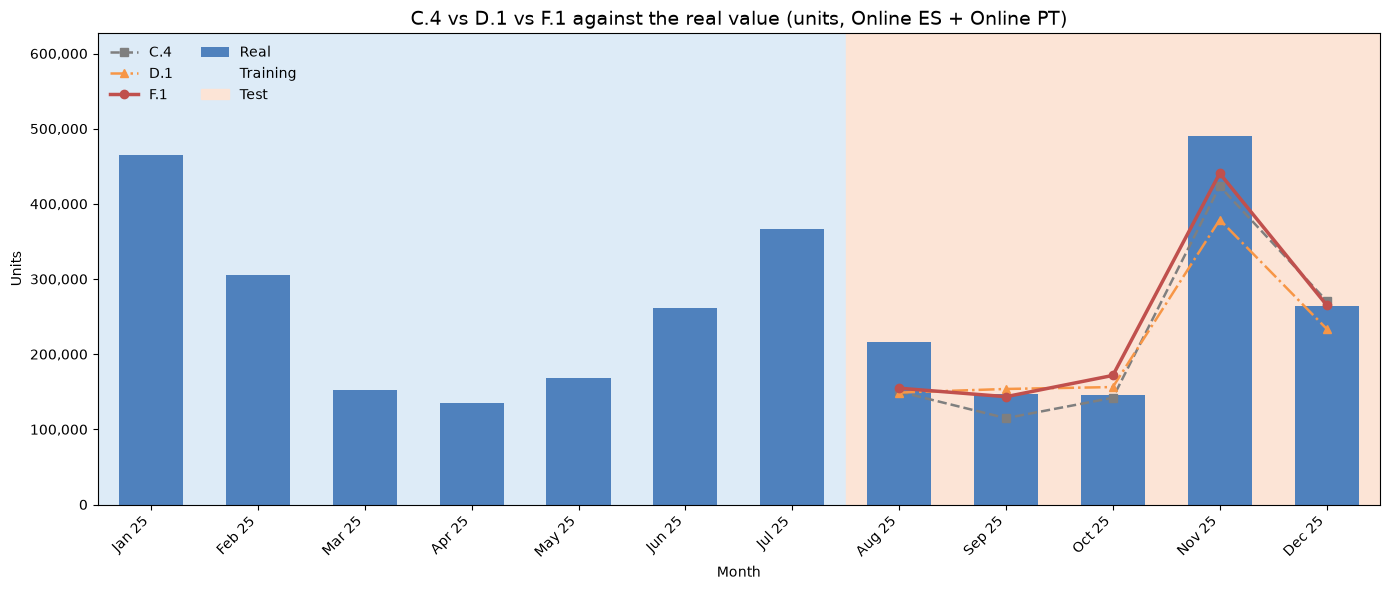

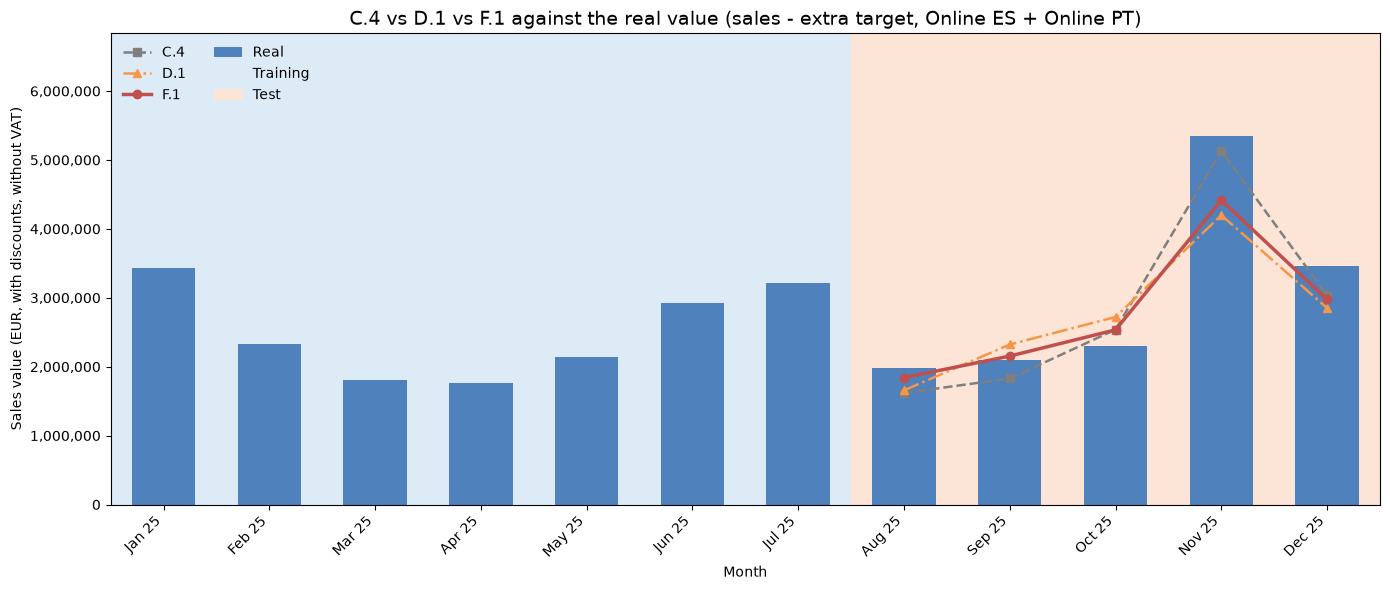

1. Overall metrics (all test days pooled; sales = extra target, not used for the model choice):


WAPE_pct  Bias_pct      RMSE   R2
target model                                   
units  C.4       22.64    -12.78  3,970.75 0.91
       D.1       22.51    -15.13  4,974.45 0.87
       F.1       19.68     -6.86  3,794.82 0.92
sales  C.4       20.03     -6.79 35,048.84 0.92
       D.1       22.99     -9.44 48,318.44 0.85
       F.1       17.19     -8.30 41,378.26 0.89

2. Change from C.4 to each model (negative WAPE and RMSE changes = better than C.4):


WAPE_pct change  Bias_pct change  RMSE change  R2 change
target model                                                          
units  D.1              -0.13            -2.36     1,003.70      -0.05
       F.1              -2.97             5.91      -175.93       0.01
sales  D.1               2.96            -2.65    13,269.60      -0.07
       F.1              -2.84            -1.51     6,329.43      -0.03

3. Daily error by month - WAPE (%):


model            C.4   D.1   F.1
target month                    
units  2025-08 30.95 31.52 29.20
       2025-09 21.98  9.92 10.25
       2025-10 12.89 15.33 25.16
       2025-11 19.45 24.17 15.86
       2025-12 27.50 23.03 21.20
sales  2025-08 20.46 17.97 13.21
       2025-09 16.67 17.09  7.47
       2025-10 20.42 30.04 15.54
       2025-11 19.72 23.56 19.97
       2025-12 22.04 23.88 22.12

4. Daily error by month - Bias (%) (positive = overestimates, negative = underestimates):


model             C.4    D.1    F.1
target month                       
units  2025-08 -30.48 -31.02 -28.33
       2025-09 -21.98   4.40  -2.56
       2025-10  -2.19   7.64  18.31
       2025-11 -13.57 -22.67 -10.06
       2025-12   2.47 -11.57   0.37
sales  2025-08 -18.22 -16.30  -6.94
       2025-09 -12.61  10.97   2.94
       2025-10  10.46  18.37  10.27
       2025-11  -3.99 -21.43 -17.38
       2025-12 -12.49 -17.80 -14.18

5. Monthly totals: actual, forecast and error of each model (error = forecast - actual):


actual forecast                     error                   \
model                        C.4      D.1      F.1     C.4      D.1     F.1   
target month                                                                  
units  2025-08   215903   150094   148926   154747  -65809   -66977  -61156   
       2025-09   147237   114870   153718   143461  -32367     6481   -3776   
       2025-10   145159   141979   156250   171731   -3180    11091   26572   
       2025-11   489972   423475   378916   440661  -66497  -111056  -49311   
       2025-12   264466   271004   233864   265453    6538   -30602     987   
sales  2025-08  1978446  1618071  1655909  1841165 -360375  -322536 -137281   
       2025-09  2092389  1828591  2321979  2153891 -263798   229590   61503   
       2025-10  2298605  2538963  2720813  2534576  240358   422207  235971   
       2025-11  5344322  5130853  4199009  4415630 -213469 -1145313 -928693   
       2025-12  3466734  3033722  2849759  2975186 -433013  -616975 -491548   

               error_pct                
model                C.4    D.1    F.1  
target month                            
units  2025-08    -30.50 -31.00 -28.30  
       2025-09    -22.00   4.40  -2.60  
       2025-10     -2.20   7.60  18.30  
       2025-11    -13.60 -22.70 -10.10  
       2025-12      2.50 -11.60   0.40  
sales  2025-08    -18.20 -16.30  -6.90  
       2025-09    -12.60  11.00   2.90  
       2025-10     10.50  18.40  10.30  
       2025-11     -4.00 -21.40 -17.40  
       2025-12    -12.50 -17.80 -14.20

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

# ---------- Chart settings ----------
PLOT_FROM = "2025-01"        # first month shown (None = full period); the forecasts only exist in the test months
# model -> (predictions table, colour, line style, marker); the first model is the reference
COMPARE = {
    "C.4": ("c4_predictions", "#7F7F7F", "--", "s"),   # reference: random forest on the daily total
    "D.1": ("d1_predictions", "#F79646", "-.", "^"),   # gradient boosting on the daily total
    "F.1": ("f1_predictions", "#C0504D", "-",  "o"),   # XGBoost by category group (sum of the groups)
}
HIGHLIGHT = "F.1"            # model drawn with a thicker line
PLOT_TARGETS = list(F1_TARGETS)   # units and sales (extra target); F.1 does not forecast orders
Y_LABELS = {"orders": "Orders", "units": "Units", "sales": "Sales value (EUR, with discounts, without VAT)"}
# ------------------------------------

for name, (var, *_style) in COMPARE.items():
    if var not in globals():
        raise RuntimeError(f"{var} not found: run the {name} model cell first.")
preds = pd.concat([globals()[var].assign(model=name) for name, (var, *_s) in COMPARE.items()], ignore_index=True)
preds = preds[preds["target"].isin(PLOT_TARGETS)]
preds["day"] = pd.to_datetime(preds["day"])
preds["month_start"] = preds["day"].dt.to_period("M").dt.to_timestamp()
model_names = list(COMPARE)

# 1. Charts: actual monthly totals (bars) and monthly forecast totals of each model (lines)
monthly_fc = preds.pivot_table(index="month_start", columns=["model", "target"], values="forecast", aggfunc="sum")
tab_all = f1_daily[PLOT_TARGETS].resample("MS").sum()
if PLOT_FROM:
    tab_all = tab_all[tab_all.index >= pd.Timestamp(f"{PLOT_FROM}-01")]
months = tab_all.index
x = list(range(len(months)))
first_test = months.get_loc(pd.Timestamp(f"{TEST_MONTHS[0]}-01"))
last_test = months.get_loc(pd.Timestamp(f"{TEST_MONTHS[-1]}-01"))

for t in PLOT_TARGETS:
    fig, ax = plt.subplots(figsize=(14, 6))
    ax.axvspan(-0.5, first_test - 0.5, color='#DDEBF7'); ax.axvspan(first_test - 0.5, last_test + 0.5, color='#FCE4D6')   # training and test
    ax.bar(x, tab_all[t], color='#4F81BD', width=0.6, label='Real')
    values = [tab_all[t].to_numpy(dtype=float)]
    for name in model_names:
        if (name, t) not in monthly_fc.columns:
            continue                                   # a model without this target is skipped
        _, colour, style, marker = COMPARE[name]
        series = monthly_fc[(name, t)].reindex(months)
        values.append(series.to_numpy(dtype=float))
        ax.plot(x, series, color=colour, linestyle=style, marker=marker,
                linewidth=2.5 if name == HIGHLIGHT else 1.8, label=name)
    ax.set_xticks(x); ax.set_xticklabels([m.strftime('%b %y') for m in months], rotation=45, ha='right')
    ax.set_xlim(-0.5, len(months) - 0.5)
    title_extra = " - extra target" if t not in TARGETS else ""
    ax.set_title(f'{" vs ".join(model_names)} against the real value ({t}{title_extra}, Online ES + Online PT)', fontsize=14)
    ax.set_xlabel('Month'); ax.set_ylabel(Y_LABELS.get(t, t.capitalize()))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{int(v):,}'))
    ax.set_ylim(0, np.nanmax(np.concatenate(values)) * 1.28)
    handles, labels = ax.get_legend_handles_labels()
    handles += [Patch(color='#DDEBF7', label='Training'), Patch(color='#FCE4D6', label='Test')]
    ax.legend(handles=handles, frameon=False, ncol=2, loc='upper left', fontsize=10)
    fig.tight_layout()
    plt.show()

# 2. Overall metrics (all test days pooled) and change from the reference model
overall = pd.DataFrame([
    {"target": t, "model": m, **error_metrics(g["actual"], g["forecast"])}
    for (m, t), g in preds.groupby(["model", "target"])
]).set_index(["target", "model"])
overall = overall.reindex(pd.MultiIndex.from_product([PLOT_TARGETS, model_names], names=["target", "model"])).dropna(how="all")
print("1. Overall metrics (all test days pooled; sales = extra target, not used for the model choice):")
display(overall.round(2))

reference = model_names[0]
change = pd.concat({
    m: overall.xs(m, level="model") - overall.xs(reference, level="model") for m in model_names[1:]
}, names=["model"]).swaplevel().reindex(PLOT_TARGETS, level=0)
change.columns = [f"{c} change" for c in change.columns]
print(f"2. Change from {reference} to each model (negative WAPE and RMSE changes = better than {reference}):")
display(change.round(2))

# 3. Daily error metrics by month: WAPE and Bias side by side
monthly_metrics = pd.DataFrame([
    {"target": t, "month": mo, "model": m, **error_metrics(g["actual"], g["forecast"])}
    for (m, t, mo), g in preds.groupby(["model", "target", "month"])
])
monthly_metrics["target"] = pd.Categorical(monthly_metrics["target"], categories=PLOT_TARGETS, ordered=True)
print("3. Daily error by month - WAPE (%):")
display(monthly_metrics.pivot_table(index=["target", "month"], columns="model", values="WAPE_pct", observed=True)[model_names].round(2))
print("4. Daily error by month - Bias (%) (positive = overestimates, negative = underestimates):")
display(monthly_metrics.pivot_table(index=["target", "month"], columns="model", values="Bias_pct", observed=True)[model_names].round(2))

# 4. Error in the monthly total: actual vs forecast total for the month and the difference
totals = preds.groupby(["target", "month", "model"]).agg(actual=("actual", "sum"), forecast=("forecast", "sum")).reset_index()
totals["error"] = totals["forecast"] - totals["actual"]
totals["error_pct"] = 100 * totals["error"] / totals["actual"]
totals["target"] = pd.Categorical(totals["target"], categories=PLOT_TARGETS, ordered=True)
monthly_totals = totals.pivot_table(index=["target", "month"], columns="model", values=["forecast", "error", "error_pct"], observed=True)
monthly_totals = monthly_totals[["forecast", "error", "error_pct"]]
for col in monthly_totals.columns:
    monthly_totals[col] = monthly_totals[col].round(1) if col[0] == "error_pct" else monthly_totals[col].round(0).astype(int)
monthly_totals.insert(0, ("actual", ""), totals.groupby(["target", "month"], observed=True)["actual"].first().round(0).astype(int))
print("5. Monthly totals: actual, forecast and error of each model (error = forecast - actual):")
display(monthly_totals)

In [11]:
# ============================================================
# Log the C.4, D.1 and F.1 runs (silver layer) to MLflow
# Each run stores: tags, parameters, error metrics for every target,
# a chart of actual vs forecast per target, the daily predictions and the settings chosen
# by cross-validation for each test month.
# Run this cell after the C.4, D.1 and F.1 model cells.
# ============================================================
import mlflow
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MLFLOW_EXPERIMENT = "ml_models_silver"
DATA_SOURCE = "silver"
MAIN_TARGETS = ["orders", "units"]        # used for the model choice; sales is an extra target
COMMON_PARAMS = {
    "data_source": DATA_SOURCE,
    "markets": "online PT + online ES",
    "movement_type": "SALE only",
    "sales_value": "AMOUNT_FIXED_RATE_W_DISC_WO_VAT (with discounts, without VAT)",
    "forecasting_rule": "data up to the last day of the month two months before",
    "inputs": "lag 364, lags 62-68, fixed campaigns relative to the previous year",
    "target_design": "deviation from previous year adjusted for recent growth (28 days ending at lag 62)",
    "cv": "up to 3 mini-tests: train on the past, 30-day gap, validate on 28 days",
}

mlflow.set_experiment(MLFLOW_EXPERIMENT)
print("MLflow server:", mlflow.get_tracking_uri())


def log_model_run(code, description, predictions, params, chosen=None, extra_tables=None):
    """Log one model's test results to MLflow: tags, params, metrics per target, plots and tables."""
    if predictions is None or len(predictions) == 0:
        raise RuntimeError(f"{code}: no predictions found, run the {code} model cell first.")
    preds = predictions.copy()
    preds["day"] = pd.to_datetime(preds["day"])
    targets = [t for t in ["orders", "units", "sales"] if t in preds["target"].unique()]

    with mlflow.start_run(run_name=f"{code}_{DATA_SOURCE}"):
        mlflow.set_tags({"model_code": code, "data_source": DATA_SOURCE,
                         "targets": ", ".join(targets),
                         "main_targets": ", ".join(t for t in targets if t in MAIN_TARGETS)})
        mlflow.log_params({"description": description,
                           "test_start": str(preds["day"].min().date()),
                           "test_end": str(preds["day"].max().date()),
                           "test_days": int(preds["day"].nunique()),
                           **COMMON_PARAMS, **params})

        # metrics per target (all test days pooled) + one chart per target
        wape = {}
        fig, axes = plt.subplots(len(targets), 1, figsize=(12, 3.5 * len(targets)), sharex=True)
        for ax, t in zip(np.atleast_1d(axes), targets):
            d = preds[preds["target"] == t].sort_values("day")
            a, f = d["actual"].to_numpy(dtype=float), d["forecast"].to_numpy(dtype=float)
            metrics = {
                f"{t}_WAPE_pct": float(100 * np.abs(a - f).sum() / a.sum()),
                f"{t}_Bias_pct": float(100 * (f - a).sum() / a.sum()),
                f"{t}_RMSE": float(np.sqrt(np.mean((a - f) ** 2))),
                f"{t}_R2": float(1 - np.sum((a - f) ** 2) / np.sum((a - a.mean()) ** 2)),
            }
            mlflow.log_metrics(metrics)
            wape[t] = metrics[f"{t}_WAPE_pct"]
            print(f"  {t:<6}", {k.replace(f'{t}_', ''): round(v, 2) for k, v in metrics.items()})
            ax.plot(d["day"], a, label="actual", color="#4F81BD")
            ax.plot(d["day"], f, label="forecast", color="#C0504D")
            ax.set_title(f"{code}: {t}" + ("" if t in MAIN_TARGETS else " (extra target)"))
            ax.legend(frameon=False)
        plt.tight_layout()
        mlflow.log_figure(fig, f"{code}_actual_vs_forecast.png")
        plt.close(fig)

        # mean WAPE of the main targets the model forecasts (orders and/or units)
        main = [t for t in targets if t in MAIN_TARGETS]
        mlflow.log_metric("main_targets_mean_WAPE_pct", float(np.mean([wape[t] for t in main])))

        # tables: daily predictions, settings chosen by cross-validation, extra tables
        mlflow.log_table(preds.assign(day=preds["day"].dt.strftime("%Y-%m-%d")), f"{code}_predictions.json")
        if chosen is not None:
            mlflow.log_table(chosen.astype({c: str for c in chosen.columns if chosen[c].dtype == object}),
                             f"{code}_chosen_settings.json")
        for name, table in (extra_tables or {}).items():
            mlflow.log_table(table, f"{code}_{name}.json")
    print(f"Logged {code}_{DATA_SOURCE} to experiment '{MLFLOW_EXPERIMENT}'\n")


# ---------- C.4 ----------
print("C.4")
log_model_run(
    code="C.4",
    description="Random Forest on the daily total, settings chosen by time-series cross-validation",
    predictions=c4_predictions,
    params={"algorithm": "RandomForestRegressor",
            "param_grid": "max_depth 4/6/8, min_samples_leaf 7/14",
            "max_features": 0.5, "trees_cv": 200, "trees_final": 500,
            "default_settings": "max_depth 6, min_samples_leaf 7"},
    chosen=c4_chosen,
)

# ---------- D.1 ----------
print("D.1")
log_model_run(
    code="D.1",
    description="Gradient Boosting on the daily total, depth and number of trees chosen by time-series cross-validation",
    predictions=d1_predictions,
    params={"algorithm": "GradientBoostingRegressor",
            "learning_rate": 0.05, "subsample": 0.8, "min_samples_leaf": 7,
            "depths": "2/3", "max_trees": 600,
            "default_settings": "max_depth 3, 300 trees"},
    chosen=d1_chosen,
)

# ---------- F.1 ----------
print("F.1")
f1_group_errors = pd.DataFrame([
    {"target": t, "group": g, **{k: float(v) for k, v in error_metrics(gdf["actual"], gdf["forecast"]).items()}}
    for (t, g), gdf in f1_group_predictions.groupby(["target", "group"])
])
log_model_run(
    code="F.1",
    description="XGBoost by category group (one row per day and group, rows weighted by group size); daily total = sum of the groups",
    predictions=f1_predictions,
    params={"algorithm": "XGBRegressor",
            "level": "day x category group (6 groups)",
            "groups": ", ".join(F1_GROUPS),
            "learning_rate": 0.05, "subsample": 0.8, "colsample_bytree": 0.8, "min_child_weight": 7,
            "param_grid": "max_depth 2/3, reg_lambda 1/10", "max_trees": 600, "tree_step": 50,
            "sample_weight": "group volume in the previous year",
            "default_settings": "max_depth 3, reg_lambda 1, 300 trees"},
    chosen=f1_chosen,
    extra_tables={"group_errors": f1_group_errors},
)

# ---------- Summary of the logged runs ----------
runs = mlflow.search_runs(experiment_names=[MLFLOW_EXPERIMENT],
                          filter_string=f"tags.data_source = '{DATA_SOURCE}'")
cols = ["tags.model_code"] + [f"metrics.{t}_{m}" for t in ["orders", "units", "sales"] for m in ["WAPE_pct", "Bias_pct"]]
cols = [c for c in cols if c in runs.columns]
print("Runs in the experiment (silver):")
display(runs[cols].rename(columns=lambda c: c.replace("metrics.", "").replace("tags.", "")).round(2))

MLflow server: http://mlflow:5000
C.4
  orders {'WAPE_pct': 17.47, 'Bias_pct': -6.45, 'RMSE': 1335.43, 'R2': 0.94}
  units  {'WAPE_pct': 22.64, 'Bias_pct': -12.78, 'RMSE': 3970.75, 'R2': 0.91}
  sales  {'WAPE_pct': 20.03, 'Bias_pct': -6.79, 'RMSE': 35048.84, 'R2': 0.92}
🏃 View run C.4_silver at: http://mlflow:5000/#/experiments/2/runs/5b9493eea4fc43118559cecd19daf15e
🧪 View experiment at: http://mlflow:5000/#/experiments/2
Logged C.4_silver to experiment 'ml_models_silver'

D.1
  orders {'WAPE_pct': 18.2, 'Bias_pct': -9.5, 'RMSE': 1639.51, 'R2': 0.9}
  units  {'WAPE_pct': 22.51, 'Bias_pct': -15.13, 'RMSE': 4974.45, 'R2': 0.87}
  sales  {'WAPE_pct': 22.99, 'Bias_pct': -9.44, 'RMSE': 48318.44, 'R2': 0.85}
🏃 View run D.1_silver at: http://mlflow:5000/#/experiments/2/runs/923bf0a67ee64070bf1602759a4741e3
🧪 View experiment at: http://mlflow:5000/#/experiments/2
Logged D.1_silver to experiment 'ml_models_silver'

F.1
  units  {'WAPE_pct': 19.68, 'Bias_pct': -6.86, 'RMSE': 3794.82, 'R2': 0.92

,model_code,orders_WAPE_pct,orders_Bias_pct,units_WAPE_pct,units_Bias_pct,sales_WAPE_pct,sales_Bias_pct
0,F.1,NaN,NaN,19.68,-6.86,17.19,-8.30
1,D.1,18.20,-9.50,22.51,-15.13,22.99,-9.44
2,C.4,17.47,-6.45,22.64,-12.78,20.03,-6.79
